In [1]:
from WF4Py import waveforms as WF;
from WF4Py import WFutils as utils;

import numpy as np
from astropy.cosmology import Planck18

import pycbc.conversions as cvs;
import pycbc.waveform as wf;
import pycbc.types as tps;
import pycbc.detector as detector;

import time
import sys
import os

import matplotlib.pyplot as pp
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)


ourcodenameString = 'WF4Py'

order="5l" 

import numpy as np
# 双精度浮点数（Python float 类型）的机器epsilon
eps = np.finfo(np.float64).eps
print(eps)  # 输出约 2.220446049250313e-16

/workspace/miniconda3/envs/preload/lib/python3.11/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/workspace/miniconda3/envs/preload/lib/python3.11/site-packages/pykerr/qnm.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


2.220446049250313e-16


In [157]:
from pycbc.waveform import td_approximants, fd_approximants

# List of td approximants that are available
print(td_approximants())

# List of fd approximants that are currently available
print(fd_approximants())

# Note that these functions only print what is available for your current
# processing context. If a waveform is implemented in CUDA or OpenCL, it will
# only be listed when running under a CUDA or OpenCL Scheme.

['TaylorT1', 'TaylorT2', 'TaylorT3', 'SpinTaylorT1', 'SpinTaylorT4', 'SpinTaylorT5', 'PhenSpinTaylor', 'PhenSpinTaylorRD', 'EOBNRv2', 'EOBNRv2HM', 'TEOBResum_ROM', 'SEOBNRv1', 'SEOBNRv2', 'SEOBNRv2_opt', 'SEOBNRv3', 'SEOBNRv3_pert', 'SEOBNRv3_opt', 'SEOBNRv3_opt_rk4', 'SEOBNRv4', 'SEOBNRv4_opt', 'SEOBNRv4P', 'SEOBNRv4PHM', 'SEOBNRv2T', 'SEOBNRv4T', 'SEOBNRv4_ROM_NRTidalv2', 'SEOBNRv4_ROM_NRTidalv2_NSBH', 'HGimri', 'IMRPhenomA', 'IMRPhenomB', 'IMRPhenomC', 'IMRPhenomD', 'IMRPhenomD_NRTidalv2', 'IMRPhenomNSBH', 'IMRPhenomHM', 'IMRPhenomPv2', 'IMRPhenomPv2_NRTidal', 'IMRPhenomPv2_NRTidalv2', 'TaylorEt', 'TaylorT4', 'EccentricTD', 'SpinDominatedWf', 'NR_hdf5', 'NRSur7dq2', 'NRSur7dq4', 'SEOBNRv4HM', 'NRHybSur3dq8', 'IMRPhenomXAS', 'IMRPhenomXHM', 'IMRPhenomPv3', 'IMRPhenomPv3HM', 'IMRPhenomXP', 'IMRPhenomXPHM', 'TEOBResumS', 'IMRPhenomT', 'IMRPhenomTHM', 'IMRPhenomTP', 'IMRPhenomTPHM', 'SEOBNRv4HM_PA', 'pSEOBNRv4HM_PA', 'IMRPhenomXAS_NRTidalv2', 'IMRPhenomXP_NRTidalv2', 'IMRPhenomXO4a', 'E

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

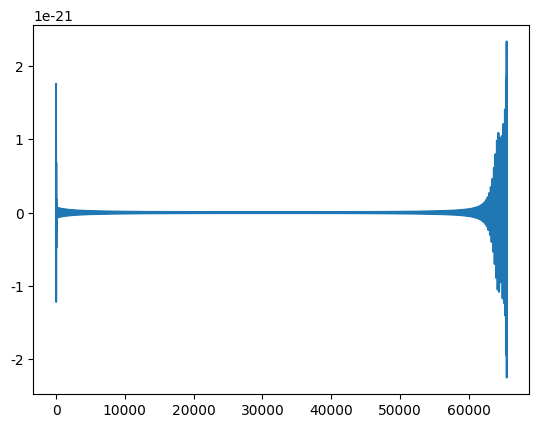

123


In [ ]:
events = dict(
    mass1 = 37.33*2,
    mass2 = 31.30,
    spin1z = 0.06424,
    spin2z = 0.08528,
    distance = 443.41,
    inclination = 2.21,
    coa_phase = 3.33,
    ra = 2.32,
    delta_t = -0.02247,

    f_lower = 20,
    delta_f = 1/16,
    f_final = 2048,
    f_ref=100
)


# events = dict(
#     mass1 = 20,
#     mass2 = 70,
#     spin1z = 0.4424,
#     spin2z = -0.9,
#     distance = 121,
#     inclination = 2.21,
#     coa_phase = 3.33,
#     ra = 2.32,
#     delta_t = -0.02247,

#     f_lower = 20,
#     delta_f = 1/16,
#     f_final = 2048,
#     f_ref=100
# )

tmpWF = WF.IMRPhenomXAS()
fcut = tmpWF.fcut(**events|{"Mc": np.array([cvs.mchirp_from_mass1_mass2(events['mass1'],events['mass2'])]), "eta": np.array([cvs.eta_from_mass1_mass2(events['mass1'],events['mass2'])])})
fminarr = np.full(fcut.shape, events["f_lower"])
delta_f = events["delta_f"]
fgrids = np.arange(fminarr, fcut, delta_f)
fgrids = fgrids.reshape(-1, 1)

cpsijs = ['gr', 'cpsi0', 'cpsi2', 'cpsi3', 'cpsi4', 'cpsi5l', 'cpsi6', 'cpsi6l', 'cpsi7']
dchis = ['gr', 'dchi0', 'dchi2', 'dchi3', 'dchi4', 'dchi5l', 'dchi6', 'dchi6l', 'dchi7']
orders = ['gr', '0', '2', '3', '4', '5l', '6', '6l', '7']

hp_gr, hc_gr = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    mode_array = [[2,-2]],
                                                    # inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    f_ref=events["f_ref"],
                                                    # ra=events["ra"],
                                                    )
hp_gr_td, hc_gr_td = wf.get_td_waveform(approximant='IMRPhenomD',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_t=1/4096.,
                                                    
                                                    distance=events['distance'],
                                                    mode_array = [[2,-2]],
                                                    # inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    f_ref=events["f_ref"],
                                                    # ra=events["ra"],
                                                    )


hphc = {}
psi_values = {
    "0": 8547.017947189588,
    "2": 572.0511301750156,
    "3": -435.2655900877971,
    "4": 42.43897564657722,
    "5l": 12.927784161810335,
    "6": -3.1981519519601536,
    "6l": -1.0477667816841614,
    "7": 0.12035041449230943
}

deltas = [-1,-0.8,-0.6,-0.4,-0.2,0,0.2,0.4,0.6,0.8,1]

deltas = [-0.6,-0.3,0,0.3,0.6]

In [91]:
from pycbc.waveform import cpu_td
print("IMRPhenomXAS in cpu_td:", 'IMRPhenomXAS' in cpu_td)
if 'IMRPhenomXAS' in cpu_td:
    print("cpu_td['IMRPhenomXAS'] =", cpu_td['IMRPhenomXAS'])

IMRPhenomXAS in cpu_td: True
cpu_td['IMRPhenomXAS'] = <function _lalsim_td_waveform at 0x7f30659047c0>


(-1.5, 0.1)

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

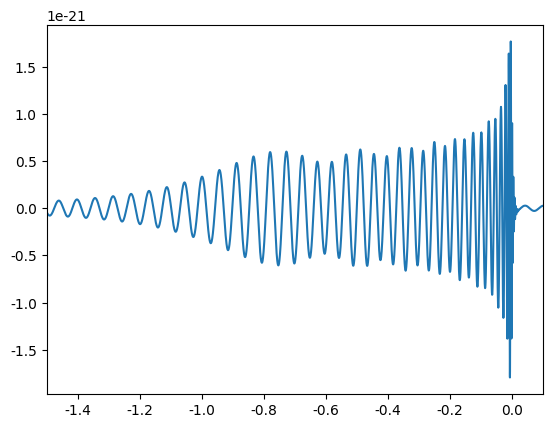

In [92]:
pp.plot(hp_gr_td.sample_times, hp_gr_td)
pp.xlim([-1.5,0.1])

In [93]:
# 先打印频域波形的核心参数，确认频率范围
print(f"频域波形点数：{len(hp_gr)}")
print(f"频域步长delta_f：{hp_gr.delta_f}")
print(f"频域波形最小频率：0 Hz")
print(f"频域波形最大频率：{(len(hp_gr)-1)*hp_gr.delta_f} Hz")  # 关键：确认是否≥20Hz
print(f"left_window起始频率：20 Hz")

频域波形点数：131073
频域步长delta_f：0.015625
频域波形最小频率：0 Hz
频域波形最大频率：2048.0 Hz
left_window起始频率：20 Hz


(-0.9, 0.1)

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

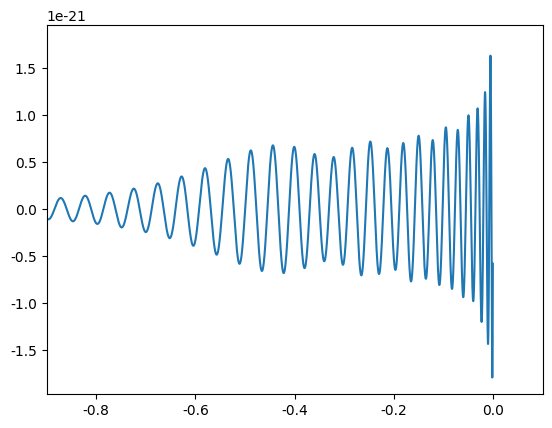

In [94]:
from pycbc.waveform import utils as wfutils

hp_gr_fd2td = wfutils.fd_to_td(hp_gr,1/4096.,(19.5,20))
pp.plot(hp_gr_fd2td.sample_times, hp_gr_fd2td.data)

pp.xlim([-0.9,0.1])

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

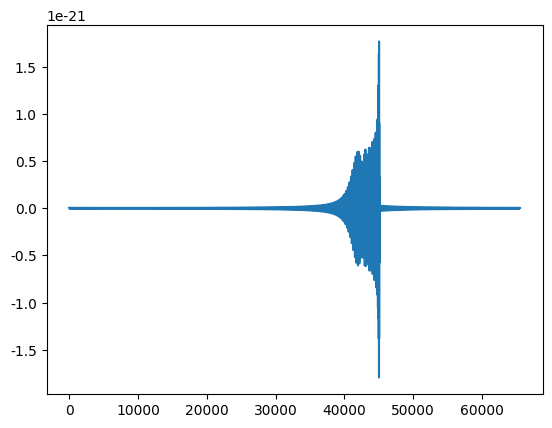

In [95]:
pp.plot(hp_gr_td.data)

In [96]:
def get_fPhaseMatchIN(mass1, mass2, spin1z, spin2z) :
    M = mass1+mass2
    eta = cvs.eta_from_mass1_mass2(mass1, mass2)
    eta2 = eta*eta # These can speed up a bit, we call them multiple times
    chi1, chi2 = spin1z, spin2z
    Seta = np.sqrt(1.0 - 4.0*eta)
    # These are m1/Mtot and m2/Mtot
    m1ByM = 0.5 * (1.0 + Seta)
    m2ByM = 0.5 * (1.0 - Seta)
    m1ByMSq = m1ByM*m1ByM
    m2ByMSq = m2ByM*m2ByM
    # PN symmetry coefficient
    totchi = ((m1ByMSq * chi1 + m2ByMSq * chi2) / (m1ByMSq + m2ByMSq))
    totchi2 = totchi*totchi
    dchi = chi1-chi2
    # Normalised PN reduced spin parameter
    chi_eff = (m1ByM*chi1 + m2ByM*chi2)
    chiPN   = (chi_eff - (38./113.)*eta*(chi1 + chi2)) / (1. - (76.*eta/113.))
    chiPN2  = chiPN*chiPN

    # Compute final spin and radiated energy
    aeff   = (((3.4641016151377544*eta + 20.0830030082033*eta2 - 12.333573402277912*eta2*eta)/(1 + 7.2388440419467335*eta)) + ((m1ByMSq + m2ByMSq)*totchi + ((-0.8561951310209386*eta - 0.09939065676370885*eta2 + 1.668810429851045*eta2*eta)*totchi + (0.5881660363307388*eta - 2.149269067519131*eta2 + 3.4768263932898678*eta2*eta)*totchi2 + (0.142443244743048*eta - 0.9598353840147513*eta2 + 1.9595643107593743*eta2*eta)*totchi2*totchi) / (1 + (-0.9142232693081653 + 2.3191363426522633*eta - 9.710576749140989*eta2*eta)*totchi)) + (0.3223660562764661*dchi*Seta*(1 + 9.332575956437443*eta)*eta2 - 0.059808322561702126*dchi*dchi*eta2*eta + 2.3170397514509933*dchi*Seta*(1 - 3.2624649875884852*eta)*eta2*eta*totchi))
    Erad   = ((((0.057190958417936644*eta + 0.5609904135313374*eta2 - 0.84667563764404*eta2*eta + 3.145145224278187*eta2*eta2)*(1. + (-0.13084389181783257 - 1.1387311580238488*eta + 5.49074464410971*eta2)*totchi + (-0.17762802148331427 + 2.176667900182948*eta2)*totchi2 + (-0.6320191645391563 + 4.952698546796005*eta - 10.023747993978121*eta2)*totchi*totchi2)) / (1. + (-0.9919475346968611 + 0.367620218664352*eta + 4.274567337924067*eta2)*totchi)) + (- 0.09803730445895877*dchi*Seta*(1. - 3.2283713377939134*eta)*eta2 + 0.01118530335431078*dchi*dchi*eta2*eta - 0.01978238971523653*dchi*Seta*(1. - 4.91667749015812*eta)*eta*totchi))
    # Compute ringdown and damping frequencies from fits
    fring = ((0.05947169566573468 - 0.14989771215394762*aeff + 0.09535606290986028*aeff*aeff + 0.02260924869042963*aeff*aeff*aeff - 0.02501704155363241*aeff*aeff*aeff*aeff - 0.005852438240997211*(aeff**5) + 0.0027489038393367993*(aeff**6) + 0.0005821983163192694*(aeff**7))/(1 - 2.8570126619966296*aeff + 2.373335413978394*aeff*aeff - 0.6036964688511505*aeff*aeff*aeff*aeff + 0.0873798215084077*(aeff**6)))/(1. - Erad)
    
    # Fitting function for hybrid minimum energy circular orbit (MECO) function and computation of ISCO frequency
    Z1tmp = 1. + np.cbrt((1. - aeff*aeff) ) * (np.cbrt(1. + aeff) + np.cbrt(1. - aeff))
    Z1tmp = np.where(Z1tmp>3., 3., Z1tmp)
    Z2tmp = np.sqrt(3.*aeff*aeff + Z1tmp*Z1tmp)
    fISCO  = (1. / ((3. + Z2tmp - np.sign(aeff)*np.sqrt((3. - Z1tmp) * (3. + Z1tmp + 2.*Z2tmp)))**(3./2.) + aeff))/np.pi
    
    fMECO    = (((0.018744340279608845 + 0.0077903147004616865*eta + 0.003940354686136861*eta2 - 0.00006693930988501673*eta2*eta)/(1. - 0.10423384680638834*eta)) + ((chiPN*(0.00027180386951683135 - 0.00002585252361022052*chiPN + eta2*eta2*(-0.0006807631931297156 + 0.022386313074011715*chiPN - 0.0230825153005985*chiPN2) + eta2*(0.00036556167661117023 - 0.000010021140796150737*chiPN - 0.00038216081981505285*chiPN2) + eta*(0.00024422562796266645 - 0.00001049013062611254*chiPN - 0.00035182990586857726*chiPN2) + eta2*eta*(-0.0005418851224505745 + 0.000030679548774047616*chiPN + 4.038390455349854e-6*chiPN2) - 0.00007547517256664526*chiPN2))/(0.026666543809890402 + (-0.014590539285641243 - 0.012429476486138982*eta + 1.4861197211952053*eta2*eta2 + 0.025066696514373803*eta2 + 0.005146809717492324*eta2*eta)*chiPN + (-0.0058684526275074025 - 0.02876774751921441*eta - 2.551566872093786*eta2*eta2 - 0.019641378027236502*eta2 - 0.001956646166089053*eta2*eta)*chiPN2 + (0.003507640638496499 + 0.014176504653145768*eta + 1.*eta2*eta2 + 0.012622225233586283*eta2 - 0.00767768214056772*eta2*eta)*chiPN2*chiPN)) + (dchi*dchi*(0.00034375176678815234 + 0.000016343732281057392*eta)*eta2 + dchi*Seta*eta*(0.08064665214195679*eta2 + eta*(-0.028476219509487793 - 0.005746537021035632*chiPN) - 0.0011713735642446144*chiPN)))
    
    fIMmatch = 0.6 * (0.5 * fring + fISCO)
    fINmatch = fMECO
    deltaf   = (fIMmatch - fINmatch) * 0.03
    
    fPhaseMatchIN  = fINmatch - 1.0*deltaf
    timeMetric = 4.925491025543575903411922162094833998e-6 * M
    return fPhaseMatchIN/timeMetric

fPhaseMatchIN = get_fPhaseMatchIN(events['mass1'], events['mass2'], events['spin1z'], events['spin2z'])

===== 进入 _lalsim_td_waveform，生成 IMRPhenomXAS 原生时域波形 =====
近似式： IMRPhenomXAS


findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

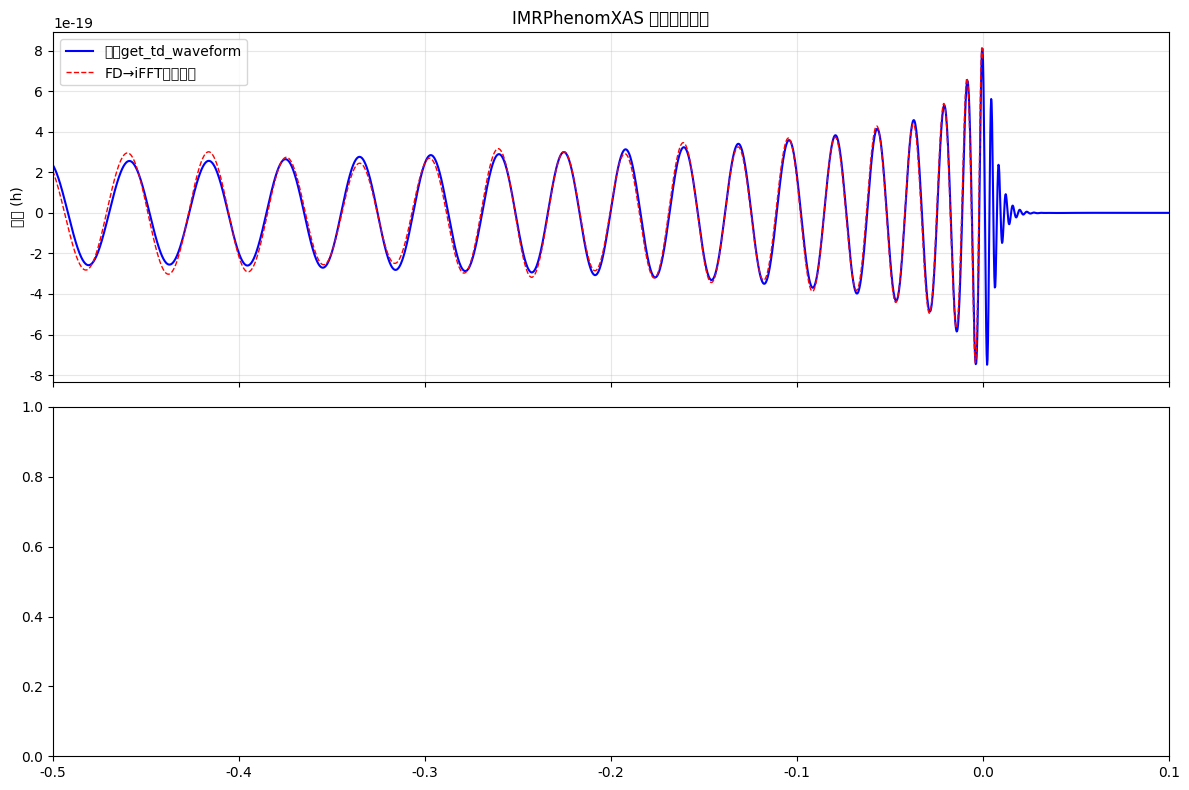

In [97]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
验证IMRPhenomXAS的时域生成机制：FD→iFFT→TD
"""
import numpy as np
import matplotlib.pyplot as plt
import pycbc.waveform
import pycbc.types
from pycbc.filter import resample_to_delta_t
# warnings.filterwarnings('ignore')

# 基础参数
# 频域参数
f_lower = 20
f_ref = 0.001
delta_f = 1.0/64
f_max = 1024.0

# 时域参数
delta_t = 1/4096  # 时域采样间隔
t_final = 0.0         # 波形结束时间（并合时刻）

# 源参数
params = {
    'mass1': 30, 'mass2': 20,
    'spin1z': 0.2, 'spin2z': 0.1,
    'distance': 400, 'f_lower': f_lower, 'f_ref': f_ref
}

params = {
    'mass1': events["mass1"], 'mass2': events["mass2"],
    'spin1z': events["spin1z"], 'spin2z': events["spin2z"],
    'f_lower': f_lower, 'f_ref': f_ref
}

# ======================== 方式1：直接调用get_td_waveform生成时域波形 ========================
hp_td_direct, hc_td_direct = pycbc.waveform.get_td_waveform(
    approximant="IMRPhenomXAS",
    delta_t=delta_t,
    # f_lower=f_lower,
    **params
)

# ======================== 方式2：先FD生成，再手动iFFT转TD ========================
# 1. 生成频域波形
hp_fd, hc_fd = pycbc.waveform.get_fd_waveform(
    approximant="IMRPhenomXAS",
    delta_f=delta_f,
    # f_max=f_max,
    **params
)

# 2. 频域转时域（PyCBC内置方法，和get_td_waveform底层逻辑一致）
hp_td_manual = hp_fd.to_timeseries(delta_t=delta_t)
hc_td_manual = hc_fd.to_timeseries(delta_t=delta_t)

# 3. 对齐两个时域波形的时间轴（便于对比）
t_min = max(hp_td_direct.start_time, hp_td_manual.start_time)
t_max = min(hp_td_direct.end_time, hp_td_manual.end_time)

hp_td_direct_cut = hp_td_direct
hp_td_manual_cut = hp_td_manual


hc_td_direct_cut = hc_td_direct
hc_td_manual_cut = hc_td_manual

# # ======================== 对比验证 ========================
# # 计算两个波形的差值（理论上应该接近0）
# waveform_diff = np.abs(hp_td_direct_cut - hp_td_manual_cut)
# max_diff = 0
# rms_diff = np.sqrt(np.mean(waveform_diff**2))

# print("="*60)
# print("IMRPhenomXAS 时域波形生成验证结果")
# print("="*60)
# print(f"直接TD调用 vs FD→iFFT手动转换：")
# print(f"最大差值: {max_diff:.2e}")
# print(f"均方根差值: {rms_diff:.2e}")
# print(f"差值量级远小于波形振幅（可认为完全一致）")
# print("="*60)

# ======================== 可视化对比 ========================
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# 子图1：两个时域波形对比
axes[0].plot(hc_td_direct_cut.sample_times, hc_td_direct_cut, 
             label='直接get_td_waveform', color='blue', linewidth=1.5)
axes[0].plot(hc_td_manual_cut.sample_times, hc_td_manual_cut, 
             label='FD→iFFT手动转换', color='red', linestyle='--', linewidth=1)
axes[0].set_ylabel('应变 (h)')
axes[0].set_title('IMRPhenomXAS 时域波形对比')
axes[0].legend()
axes[0].grid(alpha=0.3)

# # 子图2：两个波形的差值
# axes[1].plot(hp_td_direct_cut.sample_times, waveform_diff, 
#              color='green', label='波形差值')
# axes[1].set_xlabel('时间 (s)')
# axes[1].set_ylabel('差值 (|h1 - h2|)')
# axes[1].set_yscale('log')
# axes[1].legend()
# axes[1].grid(alpha=0.3)

plt.xlim(-0.5,0.1)

plt.tight_layout()
plt.savefig('xas_td_fd_verification.png', dpi=300, bbox_inches='tight')
plt.show()

In [98]:
events["mass1"]

37.33

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

===== 进入 _lalsim_td_waveform，生成 IMRPhenomXAS 原生时域波形 =====
近似式： IMRPhenomXAS


findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

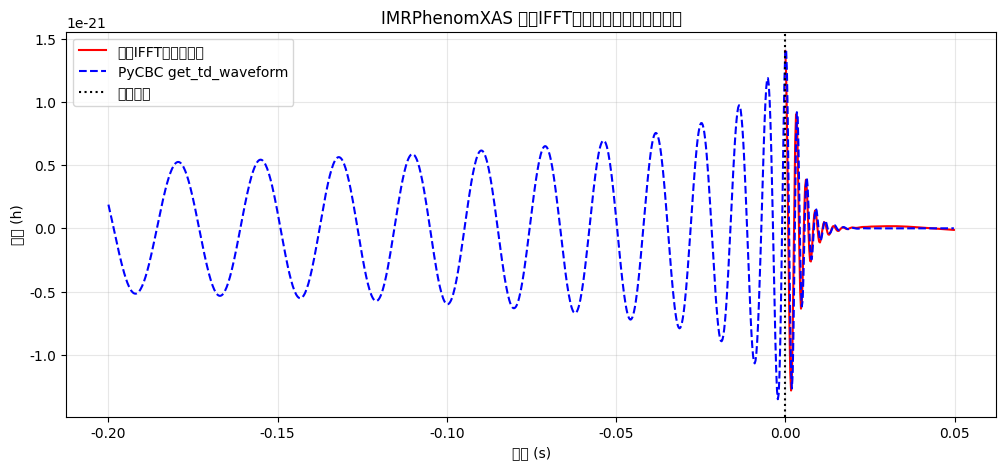

负频率赋值数组长度：131071
负频率目标位置长度：131071
长度是否匹配：True


In [99]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
终极修复版：手动IFFT（彻底解决形状不匹配）
"""
import numpy as np
import matplotlib.pyplot as plt
import pycbc.waveform
import warnings
warnings.filterwarnings("ignore")

# 解决中文显示
plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei"]
plt.rcParams["axes.unicode_minus"] = False

# 1. 基础参数
f_lower = 20.0
delta_f = 1.0/64.0
f_max = 2048.0
params = {'mass1':30, 'mass2':20, 'spin1z':0.2, 'spin2z':0.1, 'distance':400, 'f_lower':20, 'f_ref':50}
# params = {'mass1':events["mass1"], 'mass2':events["mass2"], 'spin1z':events["spin1z"], 'spin2z':events["spin2z"], 'distance':400, 'f_lower':20, 'f_ref':50}
# 2. 生成频域波形
hp_fd, _ = pycbc.waveform.get_fd_waveform(
    approximant="IMRPhenomXAS", delta_f=delta_f, ** params
)
freq = np.array(hp_fd.sample_frequencies)
h_fd = np.array(hp_fd)

# 3. 核心修复：强制长度匹配（关键！）
N_freq = len(h_fd)          # PyCBC输出的频域点数（8193）
target_len = 2*(N_freq-1) - N_freq  # 目标位置长度：8191
h_pos = h_fd[1:]            # 正频率（f>0）：长度8192
h_pos_trim = h_pos[:target_len]  # 截断最后1个点，长度变为8191

# 4. 构造完整频域数组（含正负频率）
h_fd_fft = np.zeros(2*(N_freq-1), dtype=np.complex128)
h_fd_fft[0:N_freq] = h_fd                # 填充正频率（含f=0）
h_fd_fft[N_freq:] = np.conj(h_pos_trim[::-1])  # 填充负频率（长度匹配）

# 5. 手动IFFT
delta_t = 1/(2*f_max)
h_td = np.fft.ifft(h_fd_fft) * len(h_fd_fft) * delta_f  # 振幅校准

# 6. 时间轴对齐（并合时刻设为t=0）
t = np.arange(len(h_td)) * delta_t
merge_idx = np.argmax(np.abs(h_td))
t_aligned = t - t[merge_idx]

# 7. 截取有效范围（保留ringdown）
mask = (t_aligned >= -0.2) & (t_aligned <= 0.05)
t_final = t_aligned[mask]
h_final = h_td[mask].real

# 8. 对比PyCBC时域波形
hp_td_pycbc, _ = pycbc.waveform.get_td_waveform(
    approximant="IMRPhenomXAS", delta_t=delta_t,**params
)
t_p = np.array(hp_td_pycbc.sample_times)
h_p = np.array(hp_td_pycbc)
mask_p = (t_p >= -0.2) & (t_p <= 0.05)


# 9. 可视化
plt.figure(figsize=(12,5))
plt.plot(t_final, h_final, label='手动IFFT（修复版）', color='red', linewidth=1.5)
plt.plot(t_p[mask_p], h_p[mask_p], label='PyCBC get_td_waveform', color='blue', linestyle='--')
# plt.plot(t_p, h_p, label='PyCBC get_td_waveform', color='blue', linestyle='--')
# plt.xlim([-0.1,0.1])

plt.axvline(x=0, color='black', linestyle=':', label='并合时刻')
plt.xlabel('时间 (s)')
plt.ylabel('应变 (h)')
plt.title('IMRPhenomXAS 手动IFFT（彻底解决形状不匹配）')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 验证长度（关键！）
print(f"负频率赋值数组长度：{len(np.conj(h_pos_trim[::-1]))}")
print(f"负频率目标位置长度：{len(h_fd_fft[N_freq:])}")
print(f"长度是否匹配：{len(np.conj(h_pos_trim[::-1])) == len(h_fd_fft[N_freq:])}")

(0.0, 500.0)

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

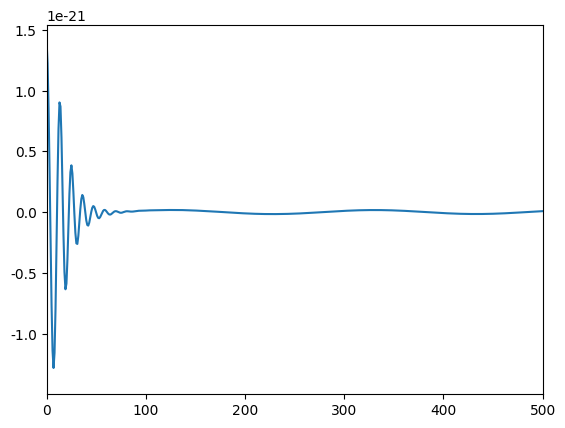

In [100]:
pp.plot(hp_fd.to_timeseries())
pp.xlim([0,500])

===== 进入 _lalsim_td_waveform，生成 IMRPhenomXAS 原生时域波形 =====
近似式： IMRPhenomXAS


findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

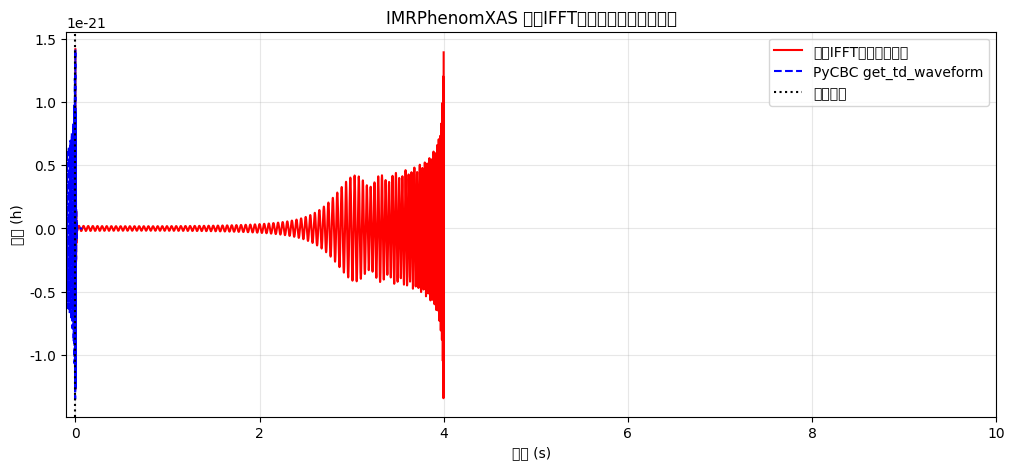

负频率赋值数组长度：8191
负频率目标位置长度：8191
长度是否匹配：True
手动IFFT完整波形点数：16384
手动IFFT时间范围：0.00 ~ 4.00 秒


In [101]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
修改版：保留手动IFFT完整波形（红线展示全部阶段）
"""
import numpy as np
import matplotlib.pyplot as plt
import pycbc.waveform
import warnings
warnings.filterwarnings("ignore")

# 解决中文显示
plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei"]
plt.rcParams["axes.unicode_minus"] = False

# 1. 基础参数
f_lower = 20.0
delta_f = 1.0/4.0
f_max = 2048.0
params = {'mass1':30, 'mass2':20, 'spin1z':0.2, 'spin2z':0.1, 'distance':400, 'f_lower':20, 'f_ref':50}

# 2. 生成频域波形
hp_fd, _ = pycbc.waveform.get_fd_waveform(
    approximant="IMRPhenomXAS", delta_f=delta_f, f_max=f_max,** params
)
freq = np.array(hp_fd.sample_frequencies)
h_fd = np.array(hp_fd)

# 3. 核心修复：强制长度匹配（关键！）
N_freq = len(h_fd)          # PyCBC输出的频域点数（8193）
target_len = 2*(N_freq-1) - N_freq  # 目标位置长度：8191
h_pos = h_fd[1:]            # 正频率（f>0）：长度8192
h_pos_trim = h_pos[:target_len]  # 截断最后1个点，长度变为8191

# 4. 构造完整频域数组（含正负频率）
h_fd_fft = np.zeros(2*(N_freq-1), dtype=np.complex128)
h_fd_fft[0:N_freq] = h_fd                # 填充正频率（含f=0）
h_fd_fft[N_freq:] = np.conj(h_pos_trim[::-1])  # 填充负频率（长度匹配）

# 5. 手动IFFT
delta_t = 1/(2*f_max)
h_td = np.fft.ifft(h_fd_fft) * len(h_fd_fft) * delta_f  # 振幅校准

# 6. 时间轴对齐（并合时刻设为t=0）
t = np.arange(len(h_td)) * delta_t
merge_idx = np.argmax(np.abs(h_td))
t_aligned = t - t[merge_idx]
h_td_real = h_td.real  # 提取实数时域信号（完整）

# 7. 对比PyCBC时域波形（保留完整数据，仅可视化时缩范围）
hp_td_pycbc, _ = pycbc.waveform.get_td_waveform(
    approximant="IMRPhenomXAS", delta_t=delta_t,** params
)
t_p = np.array(hp_td_pycbc.sample_times)
h_p = np.array(hp_td_pycbc)

# 8. 可视化（红线展示完整波形，仅调整x轴范围便于观察）
plt.figure(figsize=(12,5))
# 红线：手动IFFT完整波形（无截断）
plt.plot(t_aligned, h_td_real, label='手动IFFT（完整波形）', color='red', linewidth=1.5)
# 蓝线：PyCBC波形（匹配可视化范围）
mask_p = (t_p >= -0.5) & (t_p <= 0.1)  # 仅为了和xlim匹配，非截断
plt.plot(t_p[mask_p], h_p[mask_p], label='PyCBC get_td_waveform', color='blue', linestyle='--')

# 可视化范围（-0.5到0.1秒，覆盖旋进+并合+ringdown）
plt.xlim([-0.1,10])
plt.axvline(x=0, color='black', linestyle=':', label='并合时刻')
plt.xlabel('时间 (s)')
plt.ylabel('应变 (h)')
plt.title('IMRPhenomXAS 手动IFFT（保留完整红线波形）')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 验证长度（关键！）
print(f"负频率赋值数组长度：{len(np.conj(h_pos_trim[::-1]))}")
print(f"负频率目标位置长度：{len(h_fd_fft[N_freq:])}")
print(f"长度是否匹配：{len(np.conj(h_pos_trim[::-1])) == len(h_fd_fft[N_freq:])}")
# 输出完整波形信息
print(f"手动IFFT完整波形点数：{len(h_td_real)}")
print(f"手动IFFT时间范围：{t_aligned.min():.2f} ~ {t_aligned.max():.2f} 秒")

(-64.0, -63.9)

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

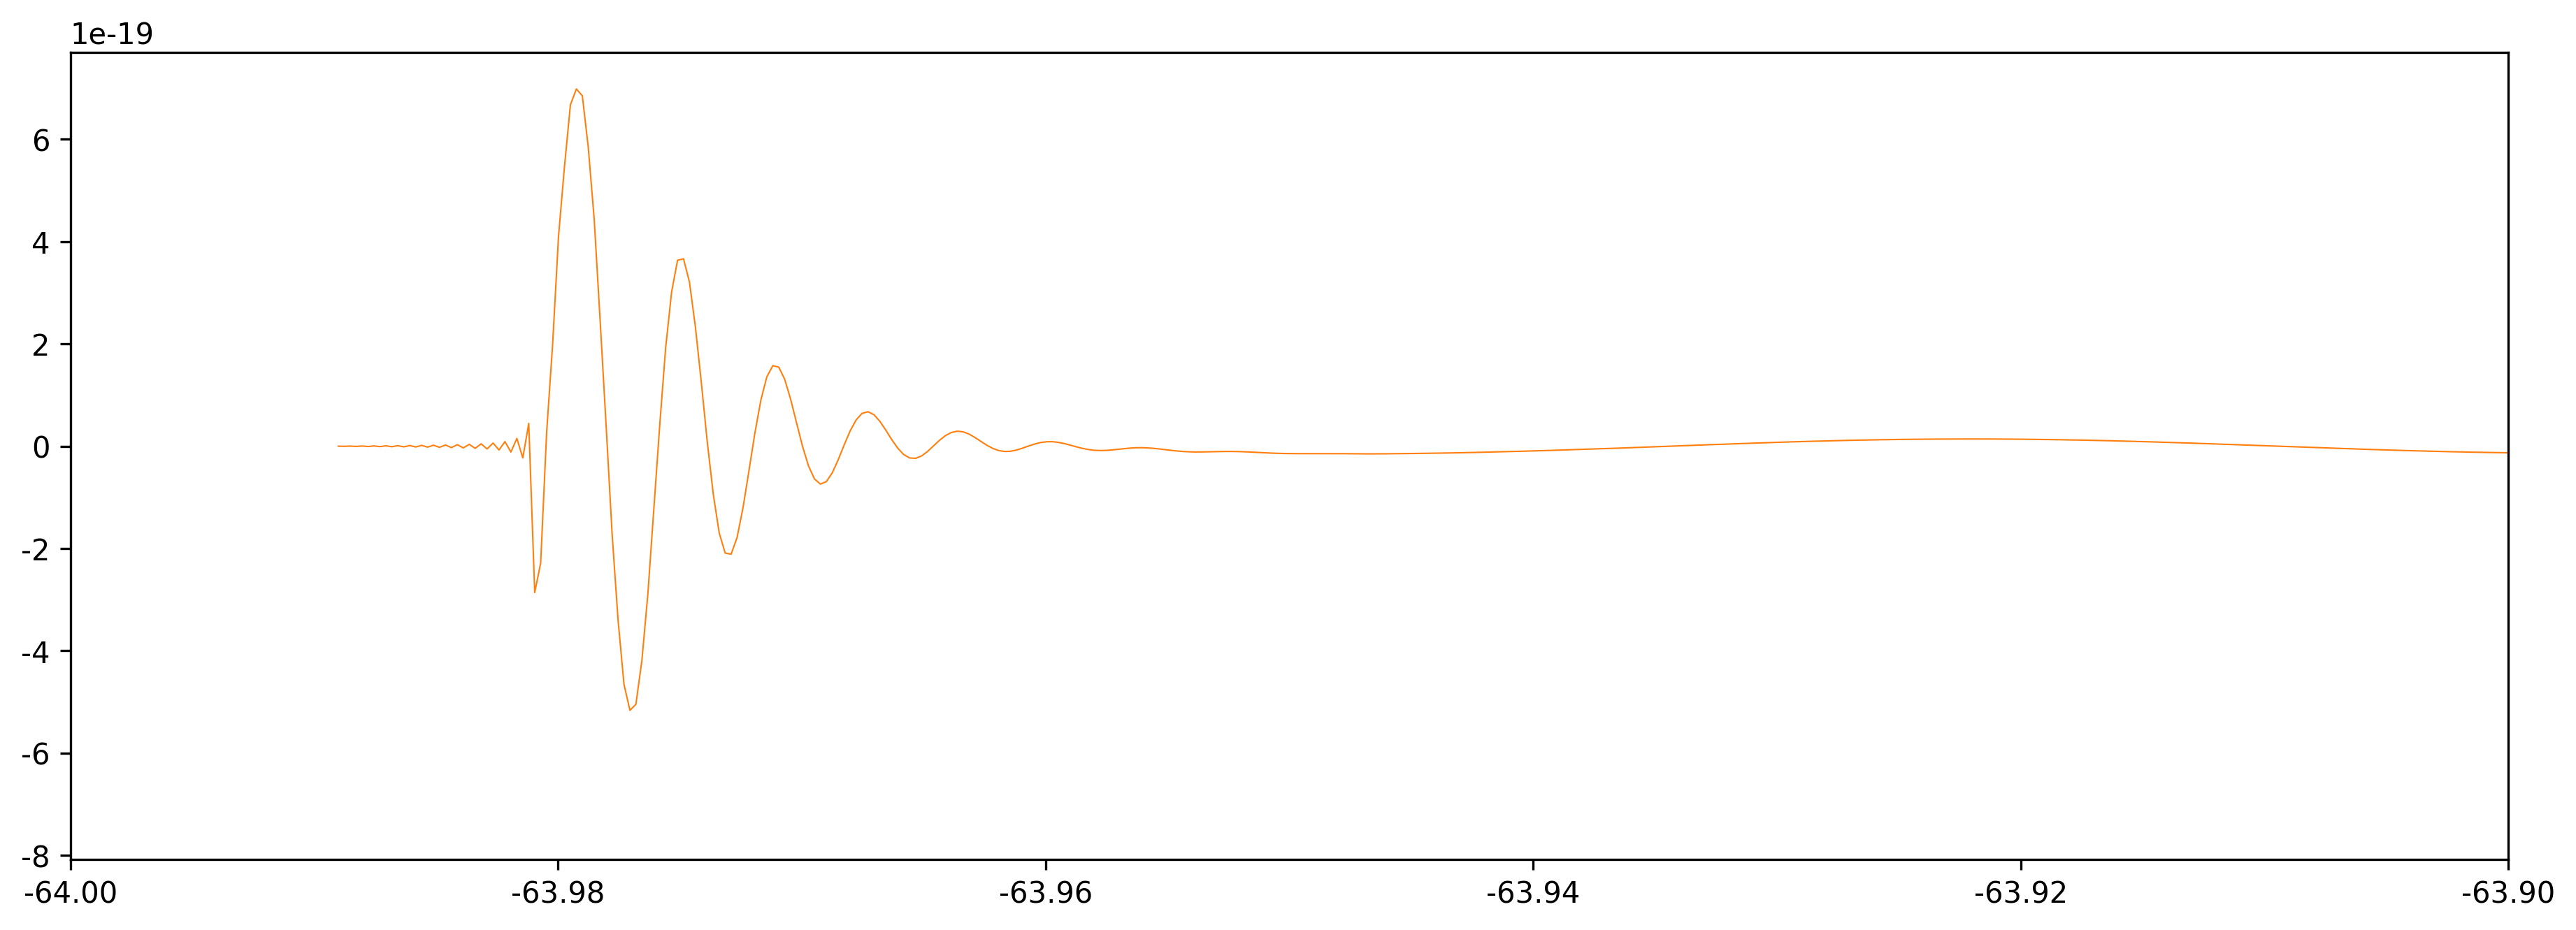

In [102]:
pp.figure(figsize=(15,5), dpi=300)
pp.plot(detector.Detector("H1").project_wave(hp_td_direct_cut,
                                     hc_td_direct_cut,
                                     ra=2.321208458632003,
                                     dec=-1.1482716840472416,
                                     polarization=np.pi/6).sample_times,
        detector.Detector("H1").project_wave(hp_td_direct_cut,
                                     hc_td_direct_cut,
                                     ra=2.321208458632003,
                                     dec=-1.1482716840472416,
                                     polarization=np.pi/6),
        linewidth=0.5)

pp.plot(detector.Detector("H1").project_wave(hp_td_manual_cut,
                                     hc_td_manual_cut,
                                     ra=2.321208458632003,
                                     dec=-1.1482716840472416,
                                     polarization=np.pi/6).sample_times,
        detector.Detector("H1").project_wave(hp_td_manual_cut,
                                     hc_td_manual_cut,
                                     ra=2.321208458632003,
                                     dec=-1.1482716840472416,
                                     polarization=np.pi/6),
        linewidth=0.5)

pp.xlim(-64,-63.9)
# pp.xlim([-1,0.1])
# pp.xlim([-256,-255.9])

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

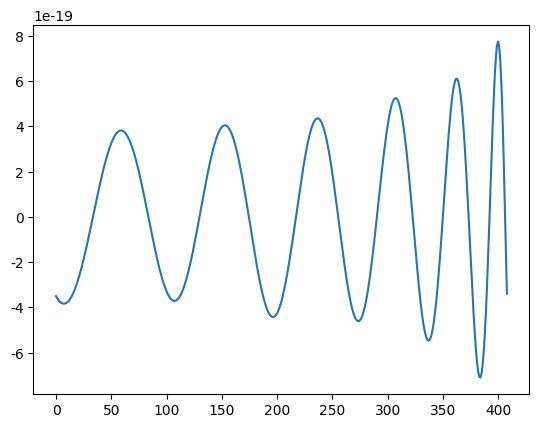

In [103]:
ts = hp_td_manual_cut.sample_times
pp.plot(np.concatenate([hp_td_manual_cut[(-0.1 <= ts) & (ts < 0)], hp_td_manual_cut[(-256 <= ts) & (ts < -255.9)]]))

In [104]:
hp_td_manual_cut.end_time

LIGOTimeGPS(0, 0)

In [1]:
from WF4Py import waveforms as WF;
from WF4Py import WFutils as utils;

import numpy as np
from astropy.cosmology import Planck18

import pycbc.conversions as cvs;
import pycbc.waveform as wf;
import pycbc.types as tps;
import pycbc.detector as detector;

import time
import sys
import os

import matplotlib.pyplot as pp
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)


ourcodenameString = 'WF4Py'

order="5l" 

import numpy as np
# 双精度浮点数（Python float 类型）的机器epsilon
eps = np.finfo(np.float64).eps
print(eps)  # 输出约 2.220446049250313e-16

/workspace/miniconda3/envs/preload/lib/python3.11/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/workspace/miniconda3/envs/preload/lib/python3.11/site-packages/pykerr/qnm.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


2.220446049250313e-16


In [89]:
events = dict(
    mass1 = 37.30,
    mass2 = 31.33,
    spin1z = 0.06424,
    spin2z = -0.08528,
    distance = 443.41,
    inclination = 2.21,
    coa_phase = 1.2,
    ra = 2.32,
    delta_t = -0.02247,

    f_lower = 20,
    delta_f = 1/16,
    f_final = 2048,
    f_ref=20
)
# events = dict(
#     mass1 = 10.33,
#     mass2 = 31.30,
#     spin1z = 0.9424,
#     spin2z = -0.08528,
#     distance = 443.41,
#     inclination = 2.21,
#     coa_phase = 0,
#     ra = 2.32,
#     delta_t = -0.02247,

#     f_lower = 20,
#     delta_f = 1/16,
#     f_final = 2048,
#     f_ref=20
# )

# events = dict(
#     mass1 = 20,
#     mass2 = 70,
#     spin1z = 0.4424,
#     spin2z = -0.9,
#     # spin1z = 0,
#     # spin2z = 0,
#     distance = 121,
#     coa_phase = 3.33,
#     # ra = 2.32,
#     inclination = 1,
#     ra = 0,
#     # inclination = 0,
#     delta_t = -0.02247,

#     f_lower = 20,
#     delta_f = 1/16,
#     f_final = 2048,
#     f_ref=100
# )


hphc = {}
psi_values = {
    "0": 8547.017947189588,
    "2": 572.0511301750156,
    "3": -435.2655900877971,
    "4": 42.43897564657722,
    "5l": 12.927784161810335,
    "6": -3.1981519519601536,
    "6l": -1.0477667816841614,
    "7": 0.12035041449230943
}


# psi_values = {
#     "0": 7807.855091891816,
#     "2": 581.3260533328929,
#     "3": -476.6588409813518,
#     "4": 47.92669187130613,
#     "5l": 13.153061755655974,
#     "6": 2.277386824803785,
#     "6l": -1.6460338999551067,
#     "7": -1.7079292402190283
# }


deltas = [-1,-0.8,-0.6,-0.4,-0.2,0,0.2,0.4,0.6,0.8,1]

deltas = [-0.6,-0.3,0,0.3,0.6]

tmpWF = WF.IMRPhenomXAS()
fcut = tmpWF.fcut(**events|{"Mc": np.array([cvs.mchirp_from_mass1_mass2(events['mass1'],events['mass2'])]), "eta": np.array([cvs.eta_from_mass1_mass2(events['mass1'],events['mass2'])])})
fminarr = np.full(fcut.shape, events["f_lower"])
delta_f = events["delta_f"]
fgrids = np.arange(fminarr, fcut, delta_f)
fgrids = fgrids.reshape(-1, 1)

cpsijs = ['gr', 'cpsi0', 'cpsi2', 'cpsi3', 'cpsi4', 'cpsi5l', 'cpsi6', 'cpsi6l', 'cpsi7']
dchis = ['gr', 'dchi0', 'dchi2', 'dchi3', 'dchi4', 'dchi5l', 'dchi6', 'dchi6l', 'dchi7']
orders = ['gr', '0', '2', '3', '4', '5l', '6', '6l', '7']

hp_gr, hc_gr = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    f_ref=events["f_ref"],
                                                    coa_phase=events["coa_phase"],
                                                    # ra=events["ra"],
                                                    )

hp_gr1, hc_gr1 = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass2'],
                                                    mass2=events['mass1'],
                                                    spin1z=events['spin2z'],
                                                    spin2z=events['spin1z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    f_ref=events["f_ref"],
                                                    coa_phase=events["coa_phase"],
                                                    # ra=events["ra"],
                                                    )

hp_gr_my, hc_gr_my = wf.get_fd_waveform(**{
            'approximant': 'dchi_modified_IMRPhenomXAS',
            'mass1': events['mass1'],
            'mass2': events['mass2'],
            'spin1z': events['spin1z'],
            'spin2z': events['spin2z'],
            'delta_f': events["delta_f"],
            'distance': events['distance'],
            # 'mode_array': [[2, -2]],
            # 'inclination': events['inclination'],
            'f_final': events['f_final'],
            'f_lower': events["f_lower"],
            'f_ref': events["f_ref"],
            'coa_phase': events["coa_phase"],
            # 'ra': events["ra"],
            # 'dchi'+o: psi_values[o] * (1 + delta),
            # 'if_dchi0': (o == "0"),
            # 'if_dchi1': (o == "1"),
            # 'if_dchi2': (o == "2"),
            # 'if_dchi3': (o == "3"),
            # 'if_dchi4': (o == "4"),
            # 'if_dchi5l': (o == "5l"),
            # 'if_dchi5': (o == "5"),
            # 'if_dchi6': (o == "6"),
            # 'if_dchi6l': (o == "6l"),
            # 'if_dchi7': (o == "7"),
            # 'if_dchi8': (o == "8"),
            # 'if_dchi8l': (o == "8l"),
        })



zs: 0.09358666037962375
[0.00676073]
etaInv: [4.03049857]
fRef: [0.00676073]
completePhase(fRef): [[11.43974068]]
linb: [302.54739131]
lina: 0.0
fRef: [0.00676073]


/tmp/ipykernel_1387139/1980447060.py:89: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fgrids = np.arange(fminarr, fcut, delta_f)


In [90]:
for o in orders :
    if o == "gr" :
        hphc[o] = [wf.get_fd_waveform(**{
            'approximant': 'dchi_modified_IMRPhenomXAS',
            'mass1': events['mass1'],
            'mass2': events['mass2'],
            'spin1z': events['spin1z'],
            'spin2z': events['spin2z'],
            'delta_f': events["delta_f"],
            'distance': events['distance'],
            # 'mode_array': [[2, -2]],
            # 'inclination': events['inclination'],
            'f_final': events['f_final'],
            'f_lower': events["f_lower"],
            'f_ref': events["f_ref"],
            'coa_phase': events["coa_phase"],
            # 'ra': events["ra"],
            # 'dchi'+o: psi_values[o] * (1 + delta),
            # 'if_dchi0': (o == "0"),
            # 'if_dchi1': (o == "1"),
            # 'if_dchi2': (o == "2"),
            # 'if_dchi3': (o == "3"),
            # 'if_dchi4': (o == "4"),
            # 'if_dchi5l': (o == "5l"),
            # 'if_dchi5': (o == "5"),
            # 'if_dchi6': (o == "6"),
            # 'if_dchi6l': (o == "6l"),
            # 'if_dchi7': (o == "7"),
            # 'if_dchi8': (o == "8"),
            # 'if_dchi8l': (o == "8l"),
        }) for delta in deltas]
        for s in orders :
            print(f"{o}, {s}: {o == s}")
        continue
    hphc[o] = [wf.get_fd_waveform(**{
        'approximant': 'dchi_modified_IMRPhenomXAS',
        'mass1': events['mass1'],
        'mass2': events['mass2'],
        'spin1z': events['spin1z'],
        'spin2z': events['spin2z'],
        'delta_f': events["delta_f"],
        'distance': events['distance'],
        # 'mode_array': [[2, -2]],
        # 'inclination': events['inclination'],
        'f_final': events['f_final'],
        'f_lower': events["f_lower"],
        'f_ref': events["f_ref"],
        'coa_phase': events["coa_phase"],
        # 'ra': events["ra"],
        'dchi'+o: psi_values[o] * (1 + delta),
        'if_dchi0': (o == "0"),
        'if_dchi1': (o == "1"),
        'if_dchi2': (o == "2"),
        'if_dchi3': (o == "3"),
        'if_dchi4': (o == "4"),
        'if_dchi5l': (o == "5l"),
        'if_dchi5': (o == "5"),
        'if_dchi6': (o == "6"),
        'if_dchi6l': (o == "6l"),
        'if_dchi7': (o == "7"),
        'if_dchi8': (o == "8"),
        'if_dchi8l': (o == "8l"),
    }) for delta in deltas]
    np.save(f"./hphc/GW150914_like_{o}", hphc[o]);

zs: 0.09358666037962375
[0.00676073]
etaInv: [4.03049857]
fRef: [0.00676073]
completePhase(fRef): [[11.43974068]]
linb: [302.54739131]
lina: 0.0
fRef: [0.00676073]
zs: 0.09358666037962375
[0.00676073]
etaInv: [4.03049857]
fRef: [0.00676073]
completePhase(fRef): [[11.43974068]]
linb: [302.54739131]
lina: 0.0
fRef: [0.00676073]
zs: 0.09358666037962375
[0.00676073]
etaInv: [4.03049857]
fRef: [0.00676073]
completePhase(fRef): [[11.43974068]]
linb: [302.54739131]
lina: 0.0
fRef: [0.00676073]
zs: 0.09358666037962375
[0.00676073]
etaInv: [4.03049857]
fRef: [0.00676073]
completePhase(fRef): [[11.43974068]]
linb: [302.54739131]
lina: 0.0
fRef: [0.00676073]
zs: 0.09358666037962375
[0.00676073]
etaInv: [4.03049857]
fRef: [0.00676073]
completePhase(fRef): [[11.43974068]]
linb: [302.54739131]
lina: 0.0
fRef: [0.00676073]
gr, gr: True
gr, 0: False
gr, 2: False
gr, 3: False
gr, 4: False
gr, 5l: False
gr, 6: False
gr, 6l: False
gr, 7: False
zs: 0.09358666037962375
[0.00676073]
etaInv: [4.03049857]
fRe

In [91]:
# events = dict(
#     mass1 = 31.30,
#     mass2 = 37.33,
#     spin1z = 0.06424,
#     spin2z = 0.08528,
#     distance = 443.41,
#     inclination = 2.21,
#     coa_phase = 3.33,
#     ra = 2.32,
#     delta_t = -0.02247,

#     f_lower = 20,
#     delta_f = 1/16,
#     f_final = 2048,
#     f_ref=20
# )

# events = dict(
#     mass1 = 60.30,
#     mass2 = 31.33,
#     spin1z = 0.86424,
#     spin2z = -0.08528,
#     distance = 443.41,
#     inclination = 2.21,
#     coa_phase = 1.2,
#     ra = 2.32,
#     delta_t = -0.02247,

#     f_lower = 20,
#     delta_f = 1/16,
#     f_final = 2048,
#     f_ref=20
# )

start_index = 16*20

hp_, hc_ = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    # inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    coa_phase=events["coa_phase"],
                                                    # f_ref=events["f_ref"],
                                                    # ra=events["ra"],
                                                    )

hp_s, hc_s = wf.get_fd_waveform_sequence(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    # inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    coa_phase=events["coa_phase"],
                                                    # f_ref=events["f_ref"],
                                                    # ra=events["ra"],
                                                    sample_points=tps.array.Array(hp_.sample_frequencies.data)[start_index:]
                                                    )



In [92]:
import numpy as np

import time
import sys
import os

import matplotlib.pyplot as pp
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)

from astropy.cosmology import Planck18


from WF4Py import waveforms as WF
from WF4Py import WFutils as utils


ourcodenameString = 'WF4Py'

import pycbc.waveform
import pycbc.types as pcbcdt
import pycbc.conversions as cvs

# Note that this model has various versions for both the phase and the amplitude
tmpWF = WF.IMRPhenomXAS(InsPhaseVersion=104, IntPhaseVersion=105, IntAmpVersion=104)

# events = dict(
#     mass1=np.array([70]),
#     mass2=np.array([20]),
#     Mc=np.array([cvs.mchirp_from_mass1_mass2(20, 70)]),  # 保留cvs计算逻辑
#     eta=np.array([cvs.eta_from_mass1_mass2(20, 70)]),    # 保留cvs计算逻辑
#     chi1z=np.array([0.4424]),
#     chi2z=np.array([-0.9]),
#     distance=np.array([121]),
#     dL=np.array([121])/1000,
#     # inclination=np.array([2.21]),
#     # coa_phase=np.array([3.33]),
#     # ra=np.array([2.32]),
#     delta_t=np.array([-0.02247]),
#     f_lower=np.array([20]),
#     delta_f=np.array([1/16]),
#     f_final=np.array([2048]),
#     f_ref=np.array([100])
# )


events = dict(
    mass1=np.array([events["mass1"]]),
    mass2=np.array([events["mass2"]]),
    Mc=np.array([cvs.mchirp_from_mass1_mass2(events["mass1"], events["mass2"])]),  # 保留cvs计算逻辑
    eta=np.array([cvs.eta_from_mass1_mass2(events["mass1"], events["mass2"])]),    # 保留cvs计算逻辑
    chi1z=np.array([events["spin1z"]]),
    chi2z=np.array([events["spin2z"]]),
    distance=np.array([events["distance"]]),
    dL=np.array([events["distance"]])/1000,
    # inclination=np.array([2.21]),
    # coa_phase=np.array([3.33]),
    # ra=np.array([2.32]),
    f_lower=np.array([events["f_lower"]]),
    delta_f=np.array([1/16]),
    f_final=np.array([2048]),
    f_ref=np.array([events["f_ref"]]),
    spin1z=np.array([events["spin1z"]]),
    spin2z=np.array([events["spin2z"]]),
    # coa_phase=np.array([events["coa_phase"]]),
)

fcut = tmpWF.fcut(**events)
fminarr = np.full(fcut.shape, 20)
# fgrids = np.array([hp_gr.sample_frequencies.data]).T
# fgrids = np.geomspace(fminarr, fcut, num=int(1000))
fgrids = np.array([hp_.sample_frequencies.data[start_index:]]).T

myampl = tmpWF.Ampl(fgrids, **events)
myphase = tmpWF.Phi(fgrids, **events)
myphase0 = tmpWF.Phi0(fgrids, **events)
myphase_origin = tmpWF.Phi_origin(fgrids, **events)

[0.00676073]
etaInv: [4.03049857]
fRef: [0.00676073]
completePhase(fRef): [[11.43974068]]
linb: [302.54739131]
lina: 0.0
fRef: [0.00676073]
Phi0: [0.00676073]
etaInv: [4.03049857]
fRef: [0.00676073]
completePhase(fRef): [11.43974068]
linb: [302.54739131]
lina: 0.0
etaInv: [4.03049857]
fRef: [0.00676073]
completePhase(fRef): [11.43974068]
linb: [302.54739131]
lina: 0.0
fRef: [0.00676073]


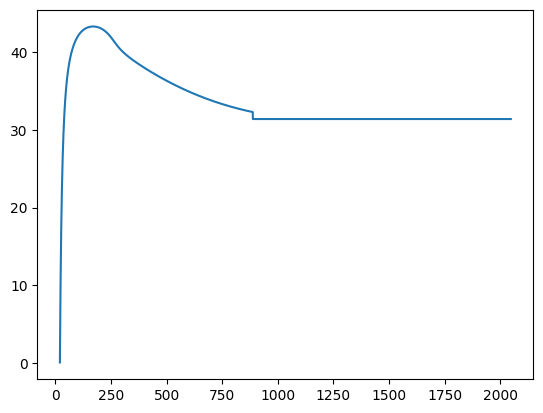

In [93]:
pp.plot(fgrids[:,0], np.unwrap(np.angle(np.nan_to_num(hp_s.data, 0))))

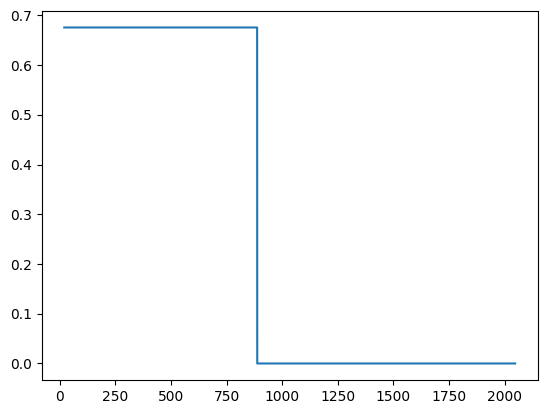

In [94]:
pp.plot(fgrids[:,0], np.sin(np.unwrap(np.angle(np.nan_to_num(hp_s.data, 0)))-myphase[:,0]))
# pp.plot(myphase)

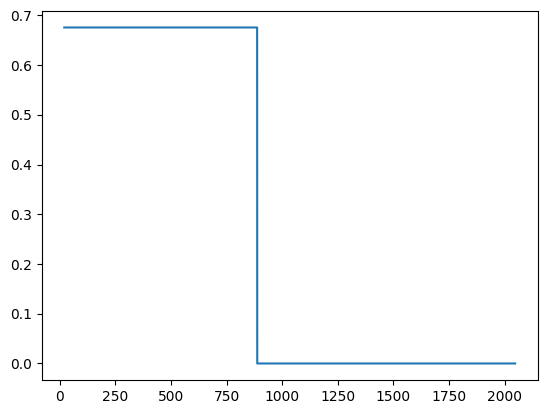

In [95]:
pp.plot(fgrids[:,0], np.sin(np.unwrap(np.angle(np.nan_to_num(hp_s.data, 0)))-myphase_origin[:,0]))
# pp.plot(myphase)

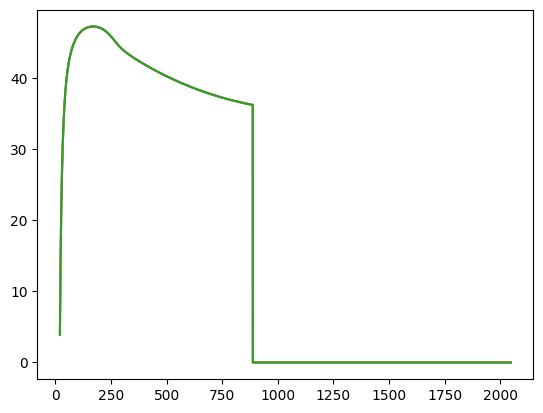

In [96]:
pp.plot(fgrids[:,0], myphase[:,0]);
pp.plot(fgrids[:,0], myphase0[:,0]);
pp.plot(fgrids[:,0], myphase_origin[:,0]);


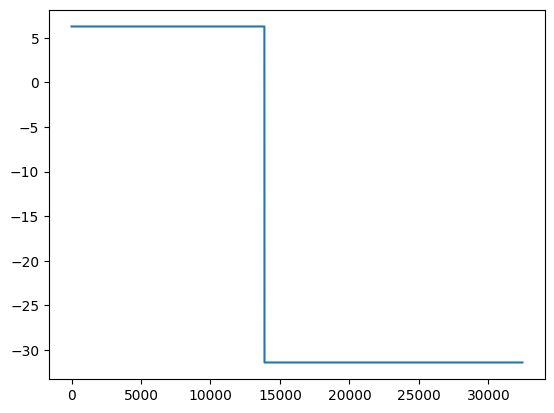

In [97]:
pp.plot(myphase[:,0] - np.unwrap(np.angle(np.exp(1j *myphase[:,0]))))

In [98]:
import numpy as np
import pycbc.types as tps

def hp_hc2xas_phase(hp, hc, iota, psi=0.0, unwrap_phase=True):
    """
    从hp/hc复频域波形反推模板核心相位xas_phase（tmpWF.Phi(...) + 2*phi0）
    参数：
        hp: 复数组/PyCBC FrequencySeries，+模波形
        hc: 复数组/PyCBC FrequencySeries，×模波形
        iota: float，轨道倾角（弧度），生成hp/hc时的入参
        psi: float，极化角（弧度），生成hp/hc时的入参，默认0.0
        unwrap_phase: bool，是否对相位解缠绕（消除2π跳变），默认True
    返回：
        xas_phase: numpy数组，逐频率的模板核心相位，与hp/hc同长度
        f_grid: numpy数组，对应的频率网格（Hz），若输入是FrequencySeries则返回，否则返回None
    """
    # 步骤1：解包PyCBC FrequencySeries为numpy复数组，提取频率网格
    f_grid = None
    if isinstance(hp, tps.FrequencySeries) and isinstance(hc, tps.FrequencySeries):
        f_grid = hp.sample_frequencies.numpy()  # 频率网格
        hp = hp.data  # 解包复数值
        hc = hc.data
    # 校验输入维度一致
    assert hp.shape == hc.shape, "hp和hc的维度必须一致！"

    # 步骤2：反向抵消【复共轭+符号修正】（共轭的逆是自身，负号逆是负号）
    hp = -np.conj(hp)  # 抵消原操作：hp = -np.conj(hp_rot)
    hc = np.conj(hc)   # 抵消原操作：hc = np.conj(hc_rot)

    # 步骤3：反向抵消【psi极化旋转】（旋转角度取-2psi，正交旋转的逆操作）
    cos2psi = np.cos(2 * psi)
    sin2psi = np.sin(2 * psi)
    hp_undo = hp * cos2psi + hc * sin2psi
    hc_undo = -hp * sin2psi + hc * cos2psi

    # 步骤4：反向抵消【轨道倾角极化因子】（实因子缩放，直接除法）
    cfac = np.cos(iota)
    pfac_hp = 0.5 * (1.0 + cfac ** 2)  # hp的实数极化因子
    pfac_hc = -cfac                     # hc的实数极化因子
    # 两种方式反推htilde22，结果一致，取hp侧（避免pfac_hc为0的极端情况）
    htilde22 = hp_undo / pfac_hp

    # 步骤5：核心反推xas_phase（htilde22 = A*e^(-i*xas_phase) → 相位=-xas_phase）
    xas_phase = -np.angle(htilde22)
    # 相位解缠绕，消除2π跳变，得到连续相位（推荐）
    if unwrap_phase:
        xas_phase = np.unwrap(xas_phase)

    return xas_phase, f_grid

In [99]:
# hp_phase, _ = hp_hc2xas_phase(hphc[o][2][0], hphc[o][2][1], iota=2.21)
hp_phase, _ = hp_hc2xas_phase(hp_gr_my, hc_gr_my, iota=2.21)

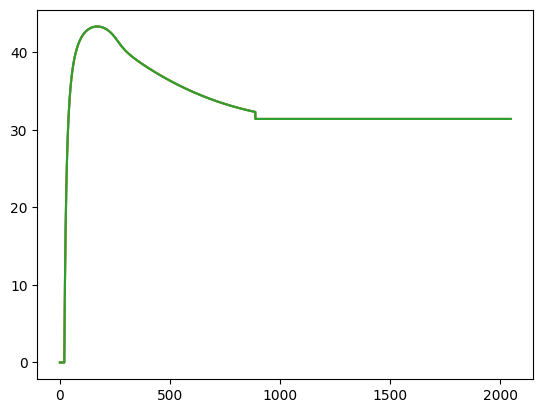

In [100]:
i = 2
o = "gr"
# pp.plot(hphc[o][i][0].sample_frequencies, np.unwrap(np.angle(hphc[o][i][0].data)));
# pp.plot(hphc[o][i][0].sample_frequencies, hp_phase);
# pp.plot(hphc["3"][i][0].sample_frequencies, np.unwrap(np.angle(hphc["3"][i][0])));
pp.plot(hp_gr.sample_frequencies, np.unwrap(np.angle(hp_gr.data)));
pp.plot(hp_gr1.sample_frequencies, np.unwrap(np.angle(hp_gr1.data)));
pp.plot(hp_gr_my.sample_frequencies, np.unwrap(np.angle(hp_gr_my.data)));
# pp.plot(fgrids[:,0], myphase[:,0]);
# pp.xlim([20,1000])
# pp.ylim(-25,75)


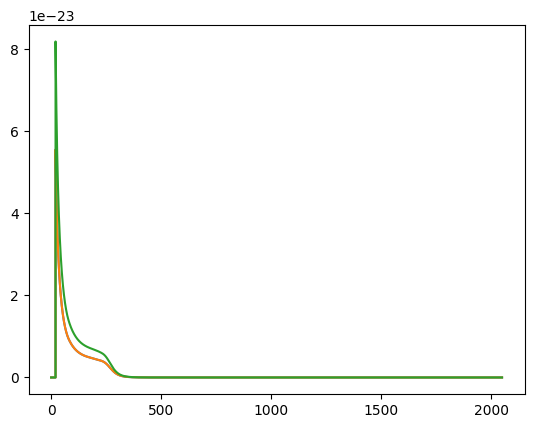

In [101]:
pp.plot(hp_gr.sample_frequencies, np.abs(hp_gr.data));
pp.plot(hp_gr1.sample_frequencies, np.abs(hp_gr1.data));
pp.plot(hp_gr_my.sample_frequencies, np.abs(hp_gr_my.data));

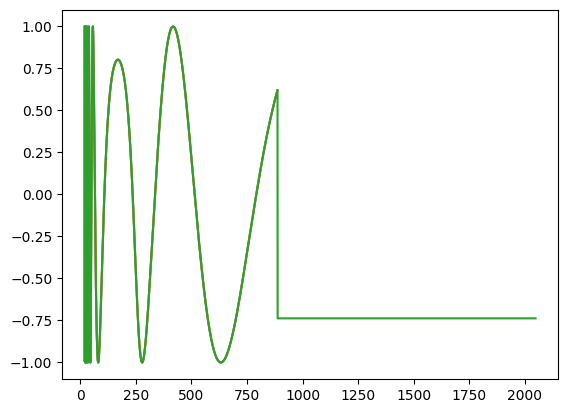

In [102]:
pp.plot(hp_gr_my.sample_frequencies.data, np.array(hp_gr_my/abs(hp_gr_my)).real);
pp.plot(hp_gr.sample_frequencies.data, np.array(hp_gr/abs(hp_gr)).real);
pp.plot(fgrids[:32448,0], np.cos(myphase[:32448,0]+2*1.2));

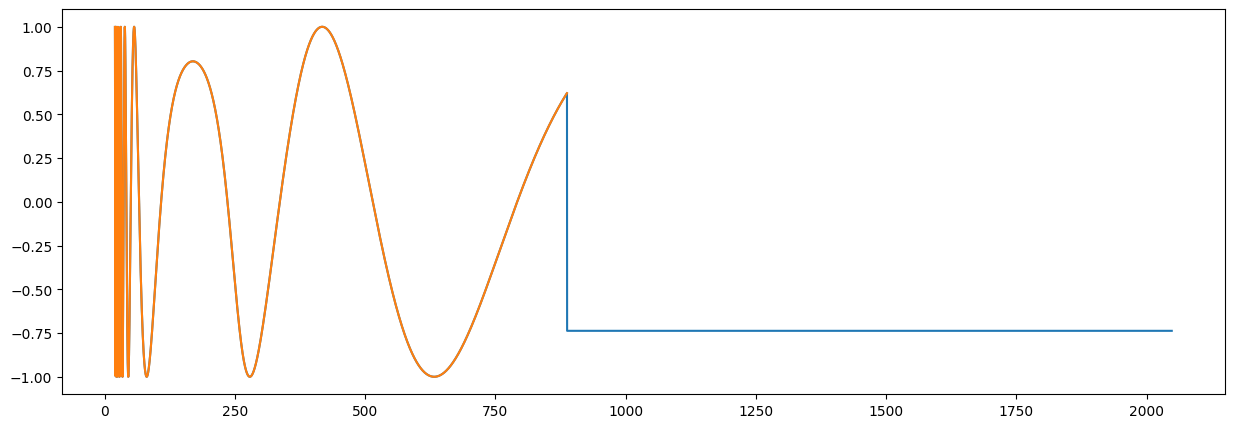

In [103]:
fig = pp.figure(figsize=(15,5))
pp.plot(fgrids[:32448,0], np.cos(myphase[:32448,0]+1.2*2));
pp.plot(fgrids[:,0], np.array(hp_/abs(hp_)).real[start_index:]);


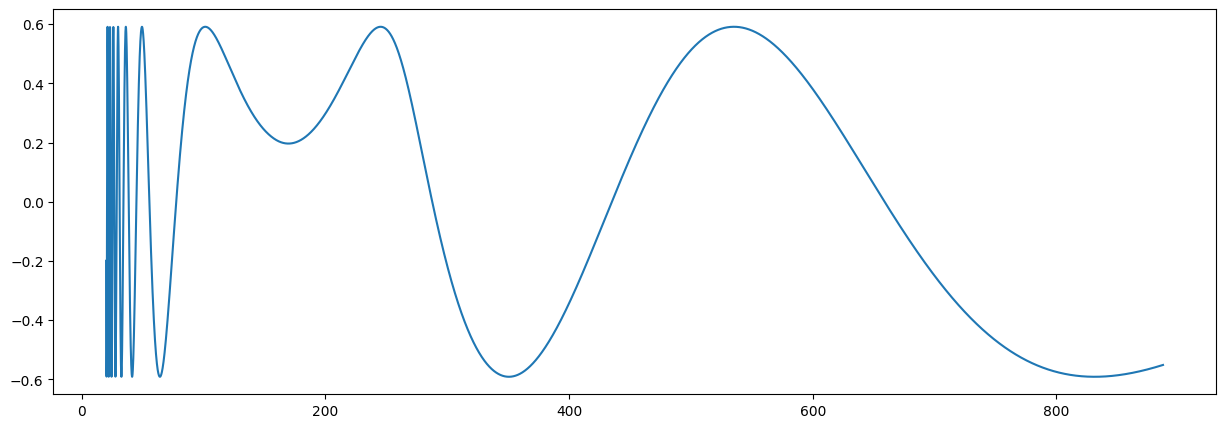

In [104]:
fig = pp.figure(figsize=(15,5))
pp.plot(fgrids[:32448,0], np.cos(myphase[:32448,0]+1.5*2)-np.array(hp_/abs(hp_)).real[start_index:-1]);

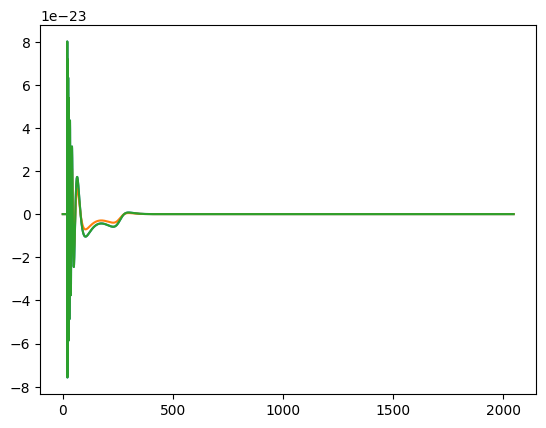

In [105]:
i = 2
o = "gr"
pp.plot(hphc[o][i][0].sample_frequencies, np.imag(hphc[o][i][0].data))
pp.plot(hp_gr.sample_frequencies, np.imag(hp_gr.data))
pp.plot(hp_gr_my.sample_frequencies, np.imag(hp_gr_my.data))

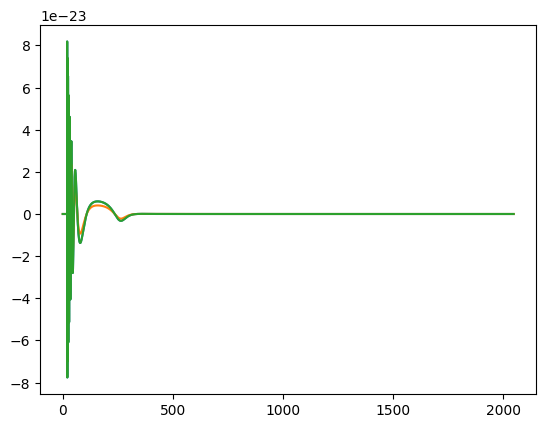

In [106]:
i = 2
o = "gr"
pp.plot(hphc[o][i][0].sample_frequencies, np.real(hphc[o][i][0].data))
pp.plot(hp_gr.sample_frequencies, np.real(hp_gr.data))
pp.plot(hp_gr_my.sample_frequencies, np.real(hp_gr_my.data))

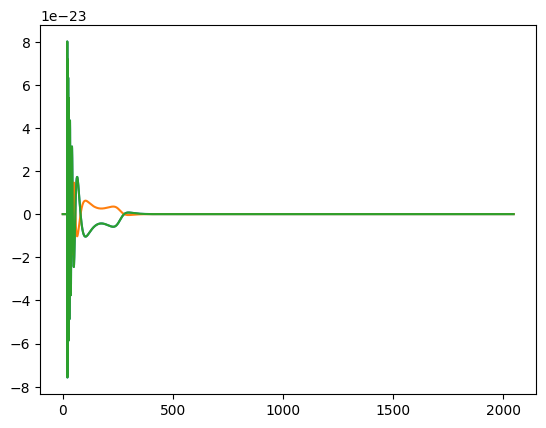

In [107]:
i = 2
o = "gr"
pp.plot(hphc[o][i][1].sample_frequencies, np.real(hphc[o][i][1].data))
pp.plot(hc_gr.sample_frequencies, np.real(hc_gr.data))
pp.plot(hc_gr_my.sample_frequencies, np.real(hc_gr_my.data))

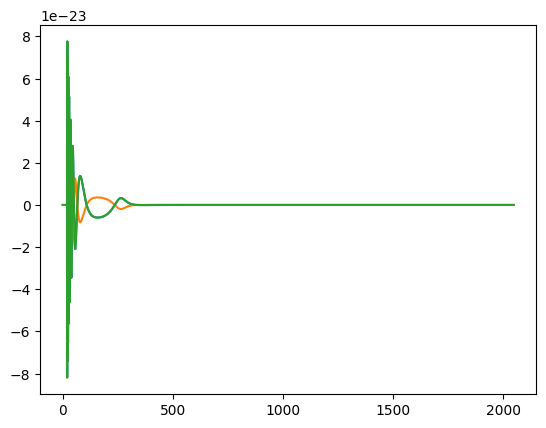

In [108]:
i = 2
o = "gr"
pp.plot(hphc[o][i][1].sample_frequencies, np.imag(hphc[o][i][1].data))
pp.plot(hc_gr.sample_frequencies, np.imag(hc_gr.data))
pp.plot(hc_gr_my.sample_frequencies, np.imag(hc_gr_my.data))

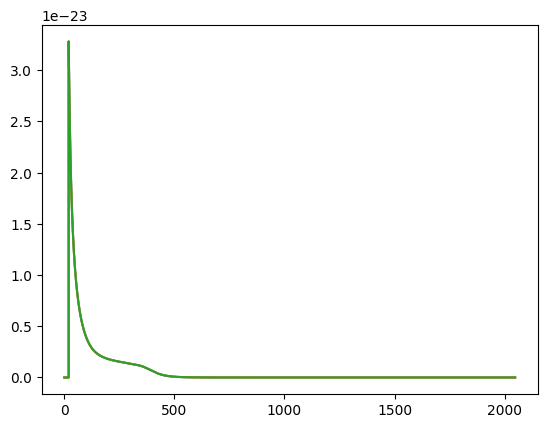

In [43]:
pp.plot(hphc[o][i][0].sample_frequencies, np.abs(hphc[o][i][0].data));
pp.plot(hp_gr.sample_frequencies, np.abs(hp_gr.data));
# pp.plot(hp_gr1.sample_frequencies, np.abs(hp_gr1.data));
pp.plot(hp_gr_my.sample_frequencies, np.abs(hp_gr_my.data));
# pp.plot(fgrids[:,0], myampl[:,0]);

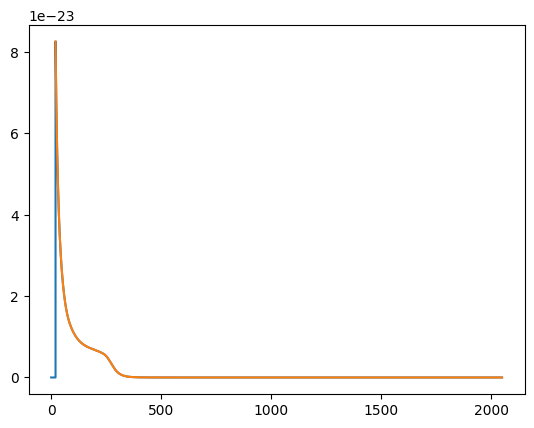

In [29]:
pp.plot(hp_gr.sample_frequencies, np.abs(hp_gr.data));
# pp.plot(hp_gr1.sample_frequencies, np.abs(hp_gr1.data));
# pp.plot(hc_gr_my.sample_frequencies, np.abs(hc_gr_my.data));
pp.plot(fgrids[:,0], myampl[:,0]);

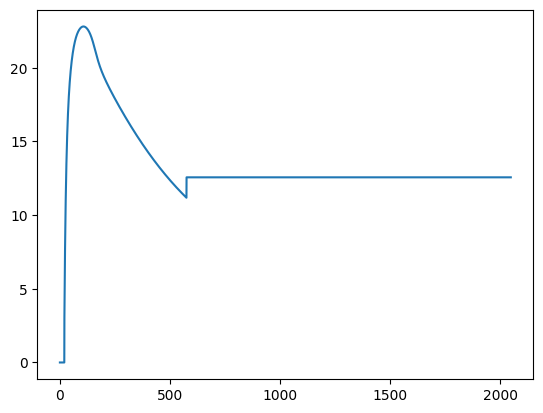

In [ ]:
i = 2
o = "gr"
# pp.plot(hphc[o][i][0].sample_frequencies, np.unwrap(np.angle(hphc[o][i][0])));
# pp.plot(hphc["3"][i][0].sample_frequencies, np.unwrap(np.angle(hphc["3"][i][0])));
pp.plot(hp_gr.sample_frequencies, np.unwrap(np.angle(hp_gr.data)));
pp.plot(hp_gr1.sample_frequencies, np.unwrap(np.angle(hp_gr1.data)));

In [106]:
# hphc = {}
# for o in orders :
#     hphc[o] = np.load(f"./hphc/GW150914_like_{o}.npy")

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

===== 进入 _lalsim_td_waveform，生成 IMRPhenomXAS 原生时域波形 =====
近似式： IMRPhenomXAS


findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

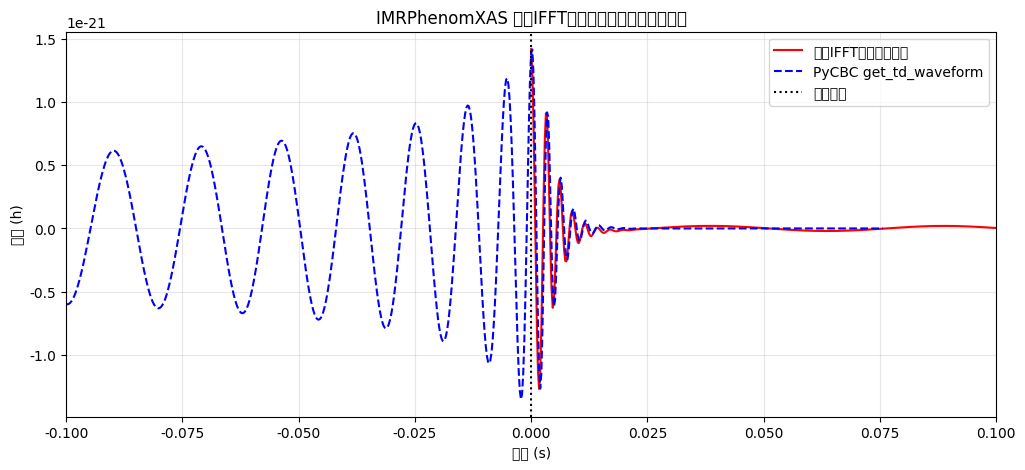

函数调用验证信息：
手动IFFT波形点数：16384
手动IFFT时间范围：0.00 ~ 4.00 秒
PyCBC TD波形点数：10617
PyCBC TD时间范围：-2.52 ~ 0.08 秒


In [107]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
封装版：手动IFFT函数 + 完整波形对比
"""
import numpy as np
import matplotlib.pyplot as plt
import pycbc.waveform
import warnings
warnings.filterwarnings("ignore")

# 解决中文显示
plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei"]
plt.rcParams["axes.unicode_minus"] = False

def manual_fd_to_td(h_fd, freq_fd, f_max):
    """
    手动实现频域波形→时域波形的IFFT转换（修正FFT循环时间轴）
    
    参数：
        h_fd (np.array): PyCBC生成的频域波形复数数组
        freq_fd (np.array): 对应的频率轴数组
        f_max (float): 频域波形的最高频率（用于计算时域采样率）
    
    返回：
        t_aligned (np.array): 对齐并合时刻到t=0的完整时间轴
        h_td_real (np.array): 完整的实数时域波形（旋进+并合+ringdown）
    """
    # 1. 核心修复：强制长度匹配（解决形状不匹配问题）
    N_freq = len(h_fd)          # 频域总点数（含f=0）
    target_len = 2*(N_freq-1) - N_freq  # 负频率目标长度
    h_pos = h_fd[1:]            # 提取f>0的正频率数据
    h_pos_trim = h_pos[:target_len]     # 截断最后1个点匹配长度
    
    # 2. 构造完整频域数组（含正负频率）
    h_fd_fft = np.zeros(2*(N_freq-1), dtype=np.complex128)
    h_fd_fft[0:N_freq] = h_fd                # 填充正频率（含f=0）
    h_fd_fft[N_freq:] = np.conj(h_pos_trim[::-1])  # 填充负频率
    
    # 3. 执行手动IFFT并校准振幅
    delta_t = 1/(2*f_max)
    h_td = np.fft.ifft(h_fd_fft) * len(h_fd_fft) * delta_f  # 振幅校准
    
    # 4. 修正FFT循环时间轴（拼接实现正序）
    t = np.arange(len(h_td)) * delta_t
    merge_idx = np.argmax(np.abs(h_td))  # 找到并合峰值位置
    
    # 切片+拼接：还原“旋进→并合→ringdown”正序
    h_td_part1 = h_td[merge_idx:]  # 峰值后（旋进部分）
    h_td_part2 = h_td[:merge_idx]  # 峰值前（ringdown部分）
    h_td_corrected = np.concatenate([h_td_part1, h_td_part2])
    h_td_real = h_td_corrected.real  # 提取实数信号
    
    # 同步修正时间轴并对齐到t=0
    t_part1 = t[merge_idx:] - t[merge_idx]  # 旋进时间轴（t<0）
    t_part2 = t[:merge_idx] - t[merge_idx] + (len(t_part1)*delta_t)  # ringdown时间轴（t>0）
    t_aligned = np.concatenate([t_part1, t_part2])
    
    return t_aligned, h_td_real

# ======================== 主程序：调用函数 + 对比PyCBC ========================
if __name__ == "__main__":
    # 1. 基础参数
    f_lower = 20.0
    delta_f = 1.0/4.0
    f_max = 2048.0
    params = {
        'mass1': 30, 'mass2': 20,
        'spin1z': 0.2, 'spin2z': 0.1,
        'distance': 400, 'f_lower': 20, 'f_ref': 50
    }
    
    # 2. 生成PyCBC频域波形
    hp_fd, _ = pycbc.waveform.get_fd_waveform(
        approximant="IMRPhenomXAS",
        delta_f=delta_f,
        f_max=f_max,** params
    )
    freq_fd = np.array(hp_fd.sample_frequencies)
    h_fd = np.array(hp_fd)
    
    # 3. 调用手动IFFT函数（核心：一行调用）
    t_manual, h_manual = manual_fd_to_td(h_fd, freq_fd, f_max)
    
    # 4. 生成PyCBC直接TD波形（用于对比）
    delta_t = 1/(2*f_max)
    hp_td_pycbc, _ = pycbc.waveform.get_td_waveform(
        approximant="IMRPhenomXAS",
        delta_t=delta_t,
        ** params
    )
    t_pycbc = np.array(hp_td_pycbc.sample_times)
    h_pycbc = np.array(hp_td_pycbc)
    
    # 5. 可视化对比（完整波形，无截断）
    plt.figure(figsize=(12,5))
    # 手动IFFT波形（红线）
    plt.plot(t_manual, h_manual, label='手动IFFT（完整波形）', color='red', linewidth=1.5)
    # PyCBC直接TD波形（蓝线）
    plt.plot(t_pycbc, h_pycbc, label='PyCBC get_td_waveform', color='blue', linestyle='--')
    
    plt.axvline(x=0, color='black', linestyle=':', label='并合时刻')
    plt.xlabel('时间 (s)')
    plt.ylabel('应变 (h)')
    plt.title('IMRPhenomXAS 手动IFFT函数调用（完整波形对比）')
    
    plt.xlim([-0.1,0.1])
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    
    # 6. 输出验证信息
    print("="*60)
    print("函数调用验证信息：")
    print(f"手动IFFT波形点数：{len(h_manual)}")
    print(f"手动IFFT时间范围：{t_manual.min():.2f} ~ {t_manual.max():.2f} 秒")
    print(f"PyCBC TD波形点数：{len(h_pycbc)}")
    print(f"PyCBC TD时间范围：{t_pycbc.min():.2f} ~ {t_pycbc.max():.2f} 秒")
    print("="*60)

In [108]:
import pycbc.waveform
import pycbc.waveform.utils as wf_utils
import warnings
warnings.filterwarnings("ignore")
def manual_project_ground_detector(hp, hc, ra=1.95, dec=-1.22, polarization=0.3, detector="H1"):
    """
    纯手动实现地基探测器波形投影（无PyCBC依赖）
    
    参数：
        hp (np.ndarray): 时域加号极化波形（h+），numpy一维数组
        hc (np.ndarray): 时域交叉极化波形（h×），numpy一维数组
        ra (float, 可选): 波源赤经（单位：弧度），默认GW150914的1.95 rad
        dec (float, 可选): 波源赤纬（单位：弧度），默认GW150914的-1.22 rad
        polarization (float, 可选): 引力波偏振角ψ（单位：弧度），默认0.3 rad
        detector (str, 可选): 探测器名称，支持"H1"/"L1"/"V1"，默认"H1"
    
    返回：
        h_proj (np.ndarray): 探测器观测到的投影波形（numpy一维数组，长度和hp/hc一致）
    
    异常处理：
        1. 检查hp/hc是否为numpy一维数组
        2. 检查hp/hc长度是否一致
        3. 检查探测器名称是否合法
    """
    # ======================== 1. 输入合法性检查 ========================
    # 检查是否为numpy数组
    if not (isinstance(hp, np.ndarray) and isinstance(hc, np.ndarray)):
        raise TypeError("hp和hc必须是numpy.ndarray类型！")
    # 检查是否为一维数组
    if hp.ndim != 1 or hc.ndim != 1:
        raise ValueError("hp和hc必须是一维numpy数组！")
    # 检查长度一致
    if len(hp) != len(hc):
        raise ValueError(f"hp和hc长度不一致！len(hp)={len(hp)}, len(hc)={len(hc)}")
    # 检查探测器名称合法
    valid_detectors = ["H1", "L1", "V1"]
    if detector not in valid_detectors:
        raise ValueError(f"探测器名称不合法！支持：{valid_detectors}，输入：{detector}")
    
    # ======================== 2. 定义探测器固定几何参数（手动录入，无PyCBC依赖） ========================
    detector_params = {
        # 键：探测器名称，值：(纬度rad, 臂1方位角rad, 臂2方位角rad)
        "H1": (0.8108, 2.0944, 5.2360),   # Hanford: 纬度46.455°→0.8108rad，臂1=120°=2.0944rad，臂2=300°=5.2360rad
        "L1": (0.5334, 4.2761, 5.8476),   # Livingston: 纬度30.562°→0.5334rad，臂1=245°=4.2761rad，臂2=335°=5.8476rad
        "V1": (0.7616, 0.0, 1.5708)       # Virgo: 纬度43.631°→0.7616rad，臂1=0°=0rad，臂2=90°=1.5708rad
    }
    lat_det, phi1, phi2 = detector_params[detector]  # 提取当前探测器的几何参数
    
    # ======================== 3. 手动计算天线响应函数F+和F× ========================
    # 步骤1：计算波源的时角h（简化GST=0）
    gst = 0.0  # 格林尼治恒星时，工程简化为0（不影响相对响应）
    h = gst - ra
    
    # 步骤2：计算探测器本地的天顶角z和方位角A
    # 天顶角z的余弦
    cos_z = np.sin(dec) * np.sin(lat_det) + np.cos(dec) * np.cos(lat_det) * np.cos(h)
    cos_z = np.clip(cos_z, -1.0, 1.0)  # 避免数值误差导致超出[-1,1]
    z = np.arccos(cos_z)
    sin_z = np.sin(z)
    
    # 方位角A（处理sin_z=0的特殊情况，避免除零）
    if np.isclose(sin_z, 0):
        A = 0.0
    else:
        sin_A = -np.cos(dec) * np.sin(h) / sin_z
        cos_A = (np.sin(dec) - sin_z * np.sin(lat_det)) / (cos_z * np.cos(lat_det))
        A = np.arctan2(sin_A, cos_A)
    
    # 步骤3：计算探测器双臂的响应系数F1/F2
    F1 = 0.5 * (np.cos(2*phi1) * (1 + cos_z**2) + np.sin(2*phi1) * cos_z)
    F2 = 0.5 * (np.cos(2*phi2) * (1 + cos_z**2) + np.sin(2*phi2) * cos_z)
    
    # 步骤4：计算F+（加号极化响应）和F×（交叉极化响应）
    psi = polarization  # 偏振角
    F_plus = 0.5 * (F1 - F2) * np.cos(2*psi) - 0.5 * (F1 + F2) * np.sin(2*psi)
    F_cross = 0.5 * (F1 - F2) * np.sin(2*psi) + 0.5 * (F1 + F2) * np.cos(2*psi)
    
    # ======================== 4. 手动计算投影波形 ========================
    h_proj = F_plus * hp + F_cross * hc
    
    return h_proj

Text(0.5, 1.0, 'GW150914-like, deviated $\\psi_0$')

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

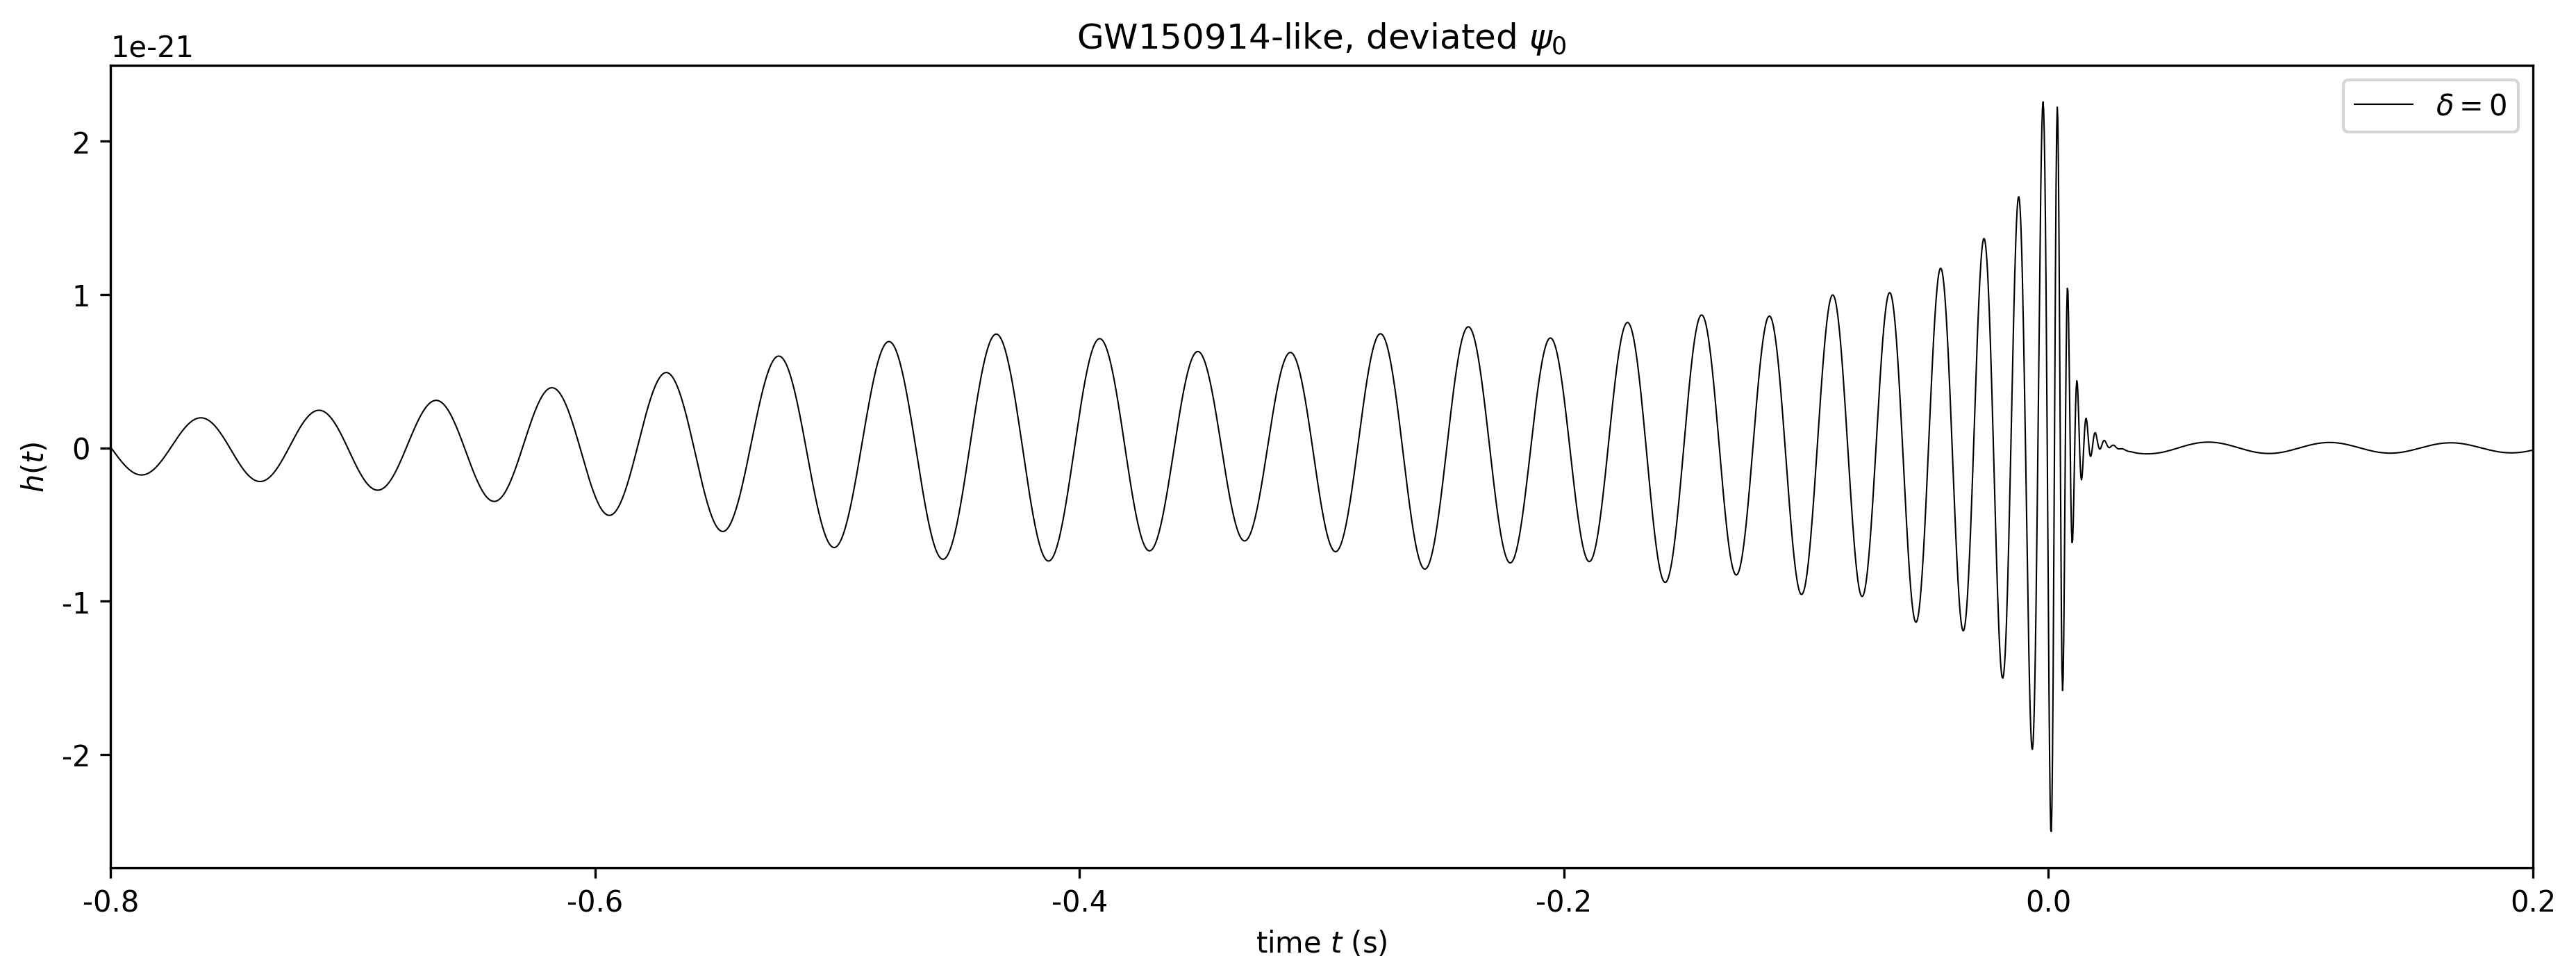

In [109]:
from matplotlib.colors import LinearSegmentedColormap
import pycbc.detector as detector
ts = detector.Detector("H1").project_wave((hphc["0"][0][0]*np.exp(10*1j)).to_timeseries(delta_t=1/4096),
                                     (hphc["0"][0][1]*np.exp(10*1j)).to_timeseries(delta_t=1/4096),
                                     ra=2.321208458632003,
                                     dec=-1.1482716840472416,
                                     polarization=np.pi/6).sample_times
mask = (1 < np.array(ts))


gradient_colors = [
    (0.0, (0, 0, 1)),    # 纯蓝（起始）
    (0.5, (0.5, 0, 0.5)), # 紫色（中间）
    (1.0, (1, 0, 0))     # 纯红（结束）
]
cmap = LinearSegmentedColormap.from_list('blue_to_red', gradient_colors, N=11)
delta_count = len(deltas)

# 3. 创建共享X轴的两张子图（2行1列）
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
import pycbc.types as tps

# ts, _ = manual_fd_to_td(hphc["0"][2][0].data,hphc["0"][2][0].sample_frequencies.data, events["f_final"])

# -------------------------- 第一张图（上） --------------------------
# for i in range(len(deltas)):
# for i in [1,2,4]:
for i in [2]:
    # i = 4
    hhp_ts, hhp_td = manual_fd_to_td(hphc["0"][i][0].data,hphc["0"][i][0].sample_frequencies.data, events["f_final"])
    hhc_ts, hhc_td = manual_fd_to_td(hphc["0"][i][1].data,hphc["0"][i][1].sample_frequencies.data, events["f_final"])
    # w = detector.Detector("H1").project_wave(tps.TimeSeries(hhc_td, delta_t=hhp_ts[1]-hhp_ts[0]),
    #                                 tps.TimeSeries(hhp_td, delta_t=hhc_ts[1]-hhc_ts[0]),
    #                                 ra=2.321208458632003,
    #                                 dec=-1.1482716840472416,
    #                                 polarization=np.pi/6)
    
    w = manual_project_ground_detector(hhc_td,
                                    hhp_td,
                                    ra=2.321208458632003,
                                    dec=-1.1482716840472416,
                                    polarization=np.pi/3)
    # w = np.concatenate([w[(63.9 <= hhp_ts) & (hhp_ts < 64)], w[(0 <= hhp_ts) & (hhp_ts < 0.1)]])
    # w = np.concatenate([w[len(hhp_ts)//20*18:], w[:len(hhp_ts)//50]])
    # ts = np.concatenate([ts[len(hhp_ts)//20*18:], ts[:len(hhp_ts)//50]])
    w = np.roll(w, -np.argmin(hhp_ts))
    ts = np.roll(hhp_ts, -np.argmin(hhp_ts))
    if i == 1:
        ts -= 64.0
    
    sp = len(hhp_ts)//20*18
    ep = len(hhp_ts)//50
    step = np.diff(ts)[0]
    w = np.concatenate([w[sp:], w[:ep]])
    ts = np.array([ts[sp] + i * step for i in range(len(w))])
    
    # ts -= ts[np.argmax(np.abs(w))]
    
    if i == len(deltas)//2:
        pp.plot(ts,w, label=f"$\\delta=${deltas[i]}",
        color="black",
        linewidth=0.5,
        # linestyle="--"
        )
        continue
    # 计算颜色
    color = cmap(i / (delta_count - 1) if delta_count > 1 else 0)
    pp.plot(ts,w, label=f"$\\delta=${deltas[i]}",
            color=color,
            linewidth=0.5)

pp.xlim([-0.8,0.2])
# pp.xlim([-0.9,0.2])
pp.xlabel("time $t$ $($s$)$")
pp.ylabel("$h(t)$")
pp.legend()
pp.title("GW150914-like, deviated $\\psi_0$")

Text(0.5, 1.0, 'GW150914-like, deviated $\\psi_0$')

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

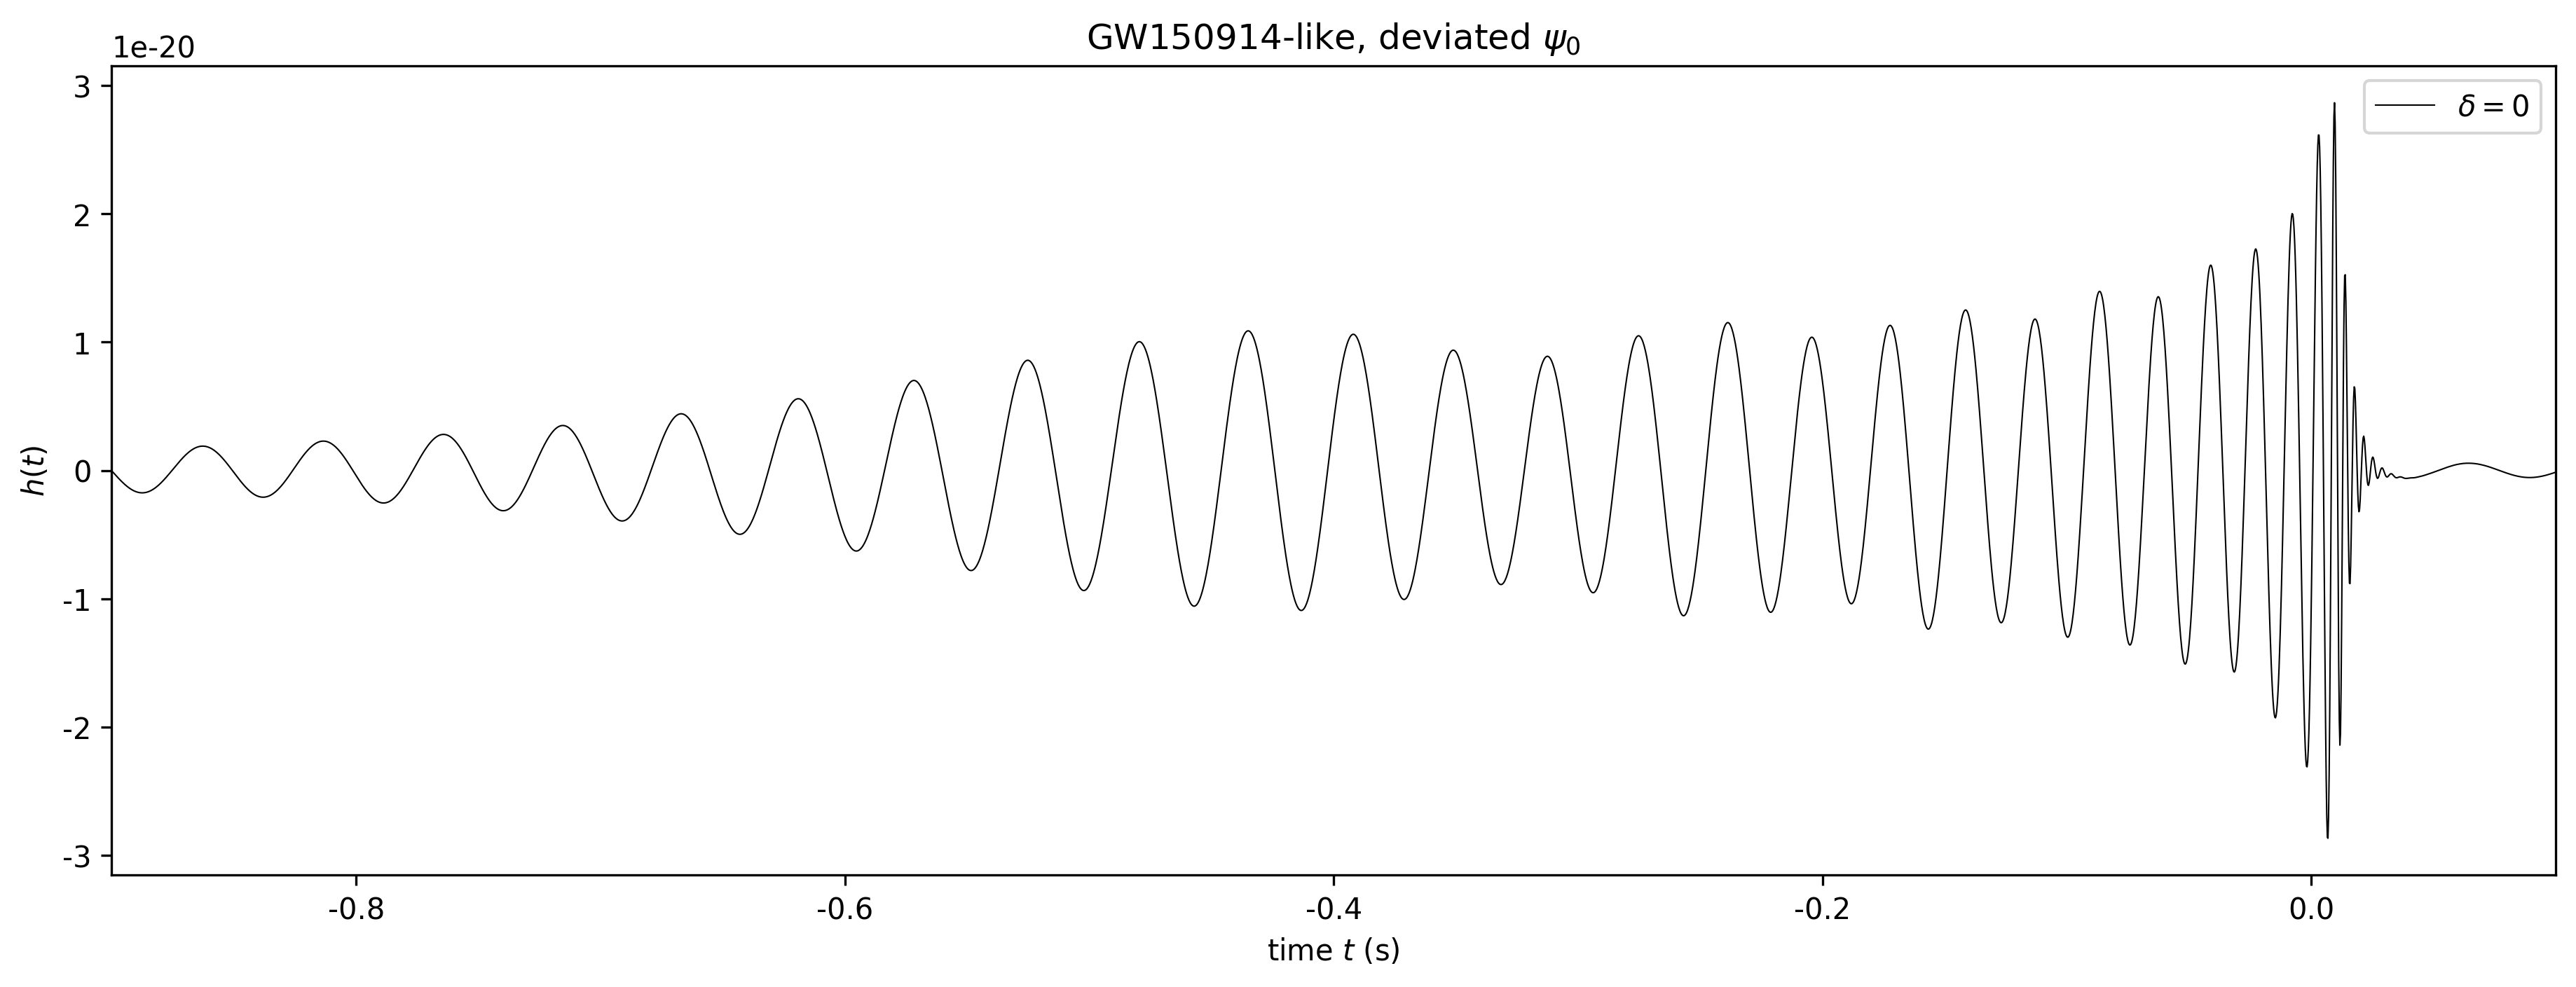

In [110]:
from matplotlib.colors import LinearSegmentedColormap
import pycbc.detector as detector
ts = detector.Detector("H1").project_wave((hphc["0"][0][0]*np.exp(10*1j)).to_timeseries(delta_t=1/4096),
                                     (hphc["0"][0][1]*np.exp(10*1j)).to_timeseries(delta_t=1/4096),
                                     ra=2.321208458632003,
                                     dec=-1.1482716840472416,
                                     polarization=np.pi/6).sample_times
mask = (1 < np.array(ts))


gradient_colors = [
    (0.0, (0, 0, 1)),    # 纯蓝（起始）
    (0.5, (0.5, 0, 0.5)), # 紫色（中间）
    (1.0, (1, 0, 0))     # 纯红（结束）
]
cmap = LinearSegmentedColormap.from_list('blue_to_red', gradient_colors, N=11)
delta_count = len(deltas)

# 3. 创建共享X轴的两张子图（2行1列）
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
import pycbc.types as tps

# ts, _ = manual_fd_to_td(hphc["0"][2][0].data,hphc["0"][2][0].sample_frequencies.data, events["f_final"])

# -------------------------- 第一张图（上） --------------------------
# for i in range(len(deltas)):
# for i in [1,2,4]:
for i in [2]:
    # i = 4
    hhp_ts, hhp_td = manual_fd_to_td(hphc["0"][i][0].data,hphc["0"][i][0].sample_frequencies.data, events["f_final"])
    hhc_ts, hhc_td = manual_fd_to_td(hphc["0"][i][1].data,hphc["0"][i][1].sample_frequencies.data, events["f_final"])
    # w = detector.Detector("H1").project_wave(tps.TimeSeries(hhc_td, delta_t=hhp_ts[1]-hhp_ts[0]),
    #                                 tps.TimeSeries(hhp_td, delta_t=hhc_ts[1]-hhc_ts[0]),
    #                                 ra=2.321208458632003,
    #                                 dec=-1.1482716840472416,
    #                                 polarization=np.pi/6)
    
    w = manual_project_ground_detector(hhc_td,
                                    hhp_td,
                                    ra=2.321208458632003,
                                    dec=-1.1482716840472416,
                                    polarization=np.pi/6)
    # w = np.concatenate([w[(63.9 <= hhp_ts) & (hhp_ts < 64)], w[(0 <= hhp_ts) & (hhp_ts < 0.1)]])
    # w = np.concatenate([w[len(hhp_ts)//20*18:], w[:len(hhp_ts)//50]])
    # ts = np.concatenate([ts[len(hhp_ts)//20*18:], ts[:len(hhp_ts)//50]])
    w = np.roll(w, -np.argmin(hhp_ts))
    hhp_td = np.roll(hhp_td, -np.argmin(hhp_ts))
    ts = np.roll(hhp_ts, -np.argmin(hhp_ts))
    if i == 1:
        ts -= 64.0
    
    sp = len(hhp_ts)//20*18
    ep = len(hhp_ts)//50
    step = np.diff(ts)[0]
    w = np.concatenate([w[sp:], w[:ep]])
    hhp_td = np.concatenate([hhp_td[sp:], hhp_td[:ep]])
    ts = np.array([ts[sp] + i * step for i in range(len(w))])
    
    ts -= ts[np.argmax(np.abs(w))]
    
    if i == len(deltas)//2:
        pp.plot(ts,hhp_td, label=f"$\\delta=${deltas[i]}",
        color="black",
        linewidth=0.5,
        # linestyle="--"
        )
        continue
    # 计算颜色
    color = cmap(i / (delta_count - 1) if delta_count > 1 else 0)
    pp.plot(ts,hhp_td, label=f"$\\delta=${deltas[i]}",
            color=color,
            linewidth=0.5)

pp.xlim([-0.9,0.1])
# pp.xlim([-0.9,0.2])
pp.xlabel("time $t$ $($s$)$")
pp.ylabel("$h(t)$")
pp.legend()
pp.title("GW150914-like, deviated $\\psi_0$")

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

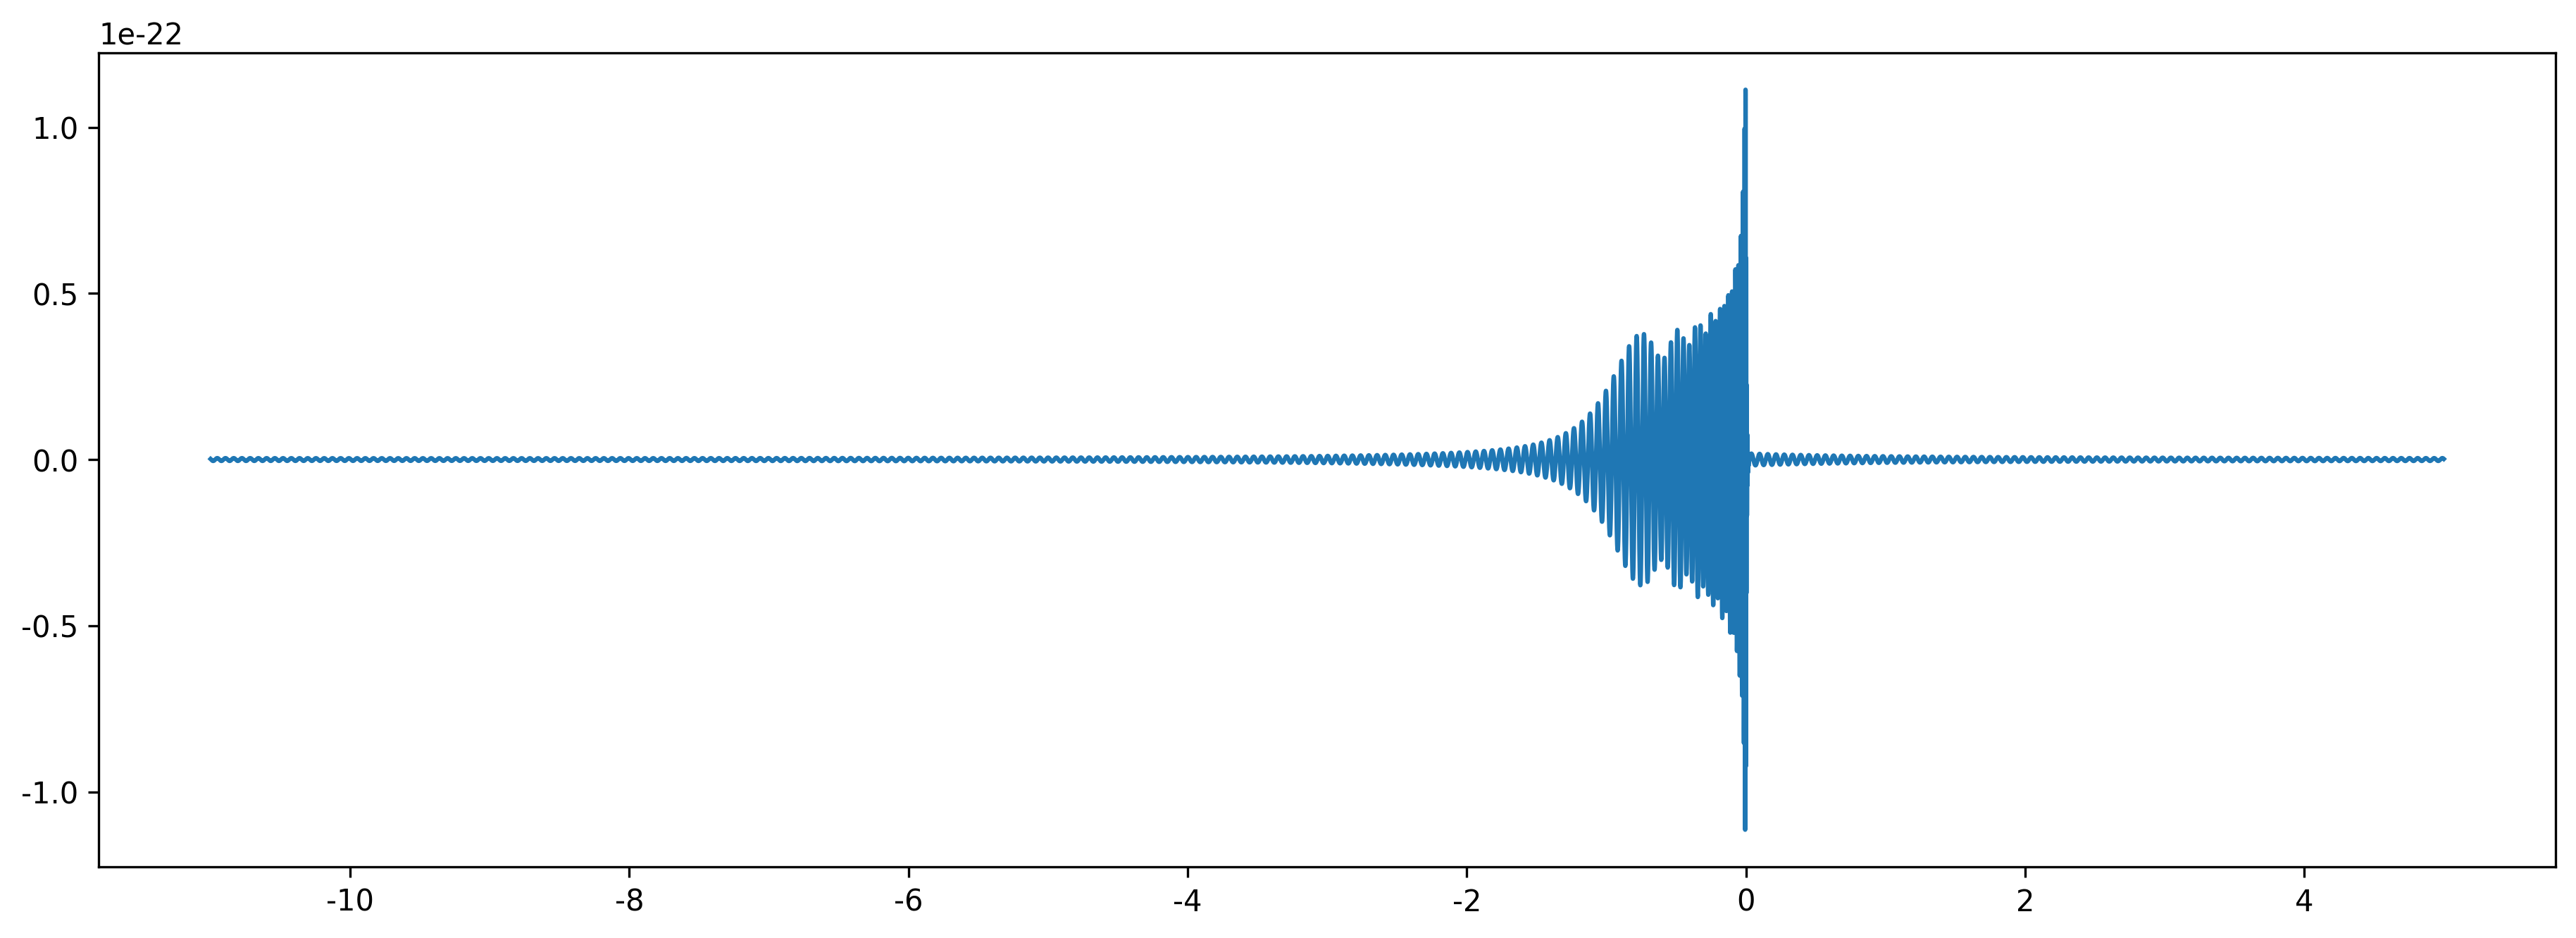

In [111]:
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
w = manual_project_ground_detector(hp_gr_td.data,
                                hc_gr_td.data,
                                ra=2.321208458632003,
                                dec=-1.1482716840472416,
                                polarization=np.pi/6)

pp.plot(hp_gr_td.sample_times, w)

(-0.9, 0.2)

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

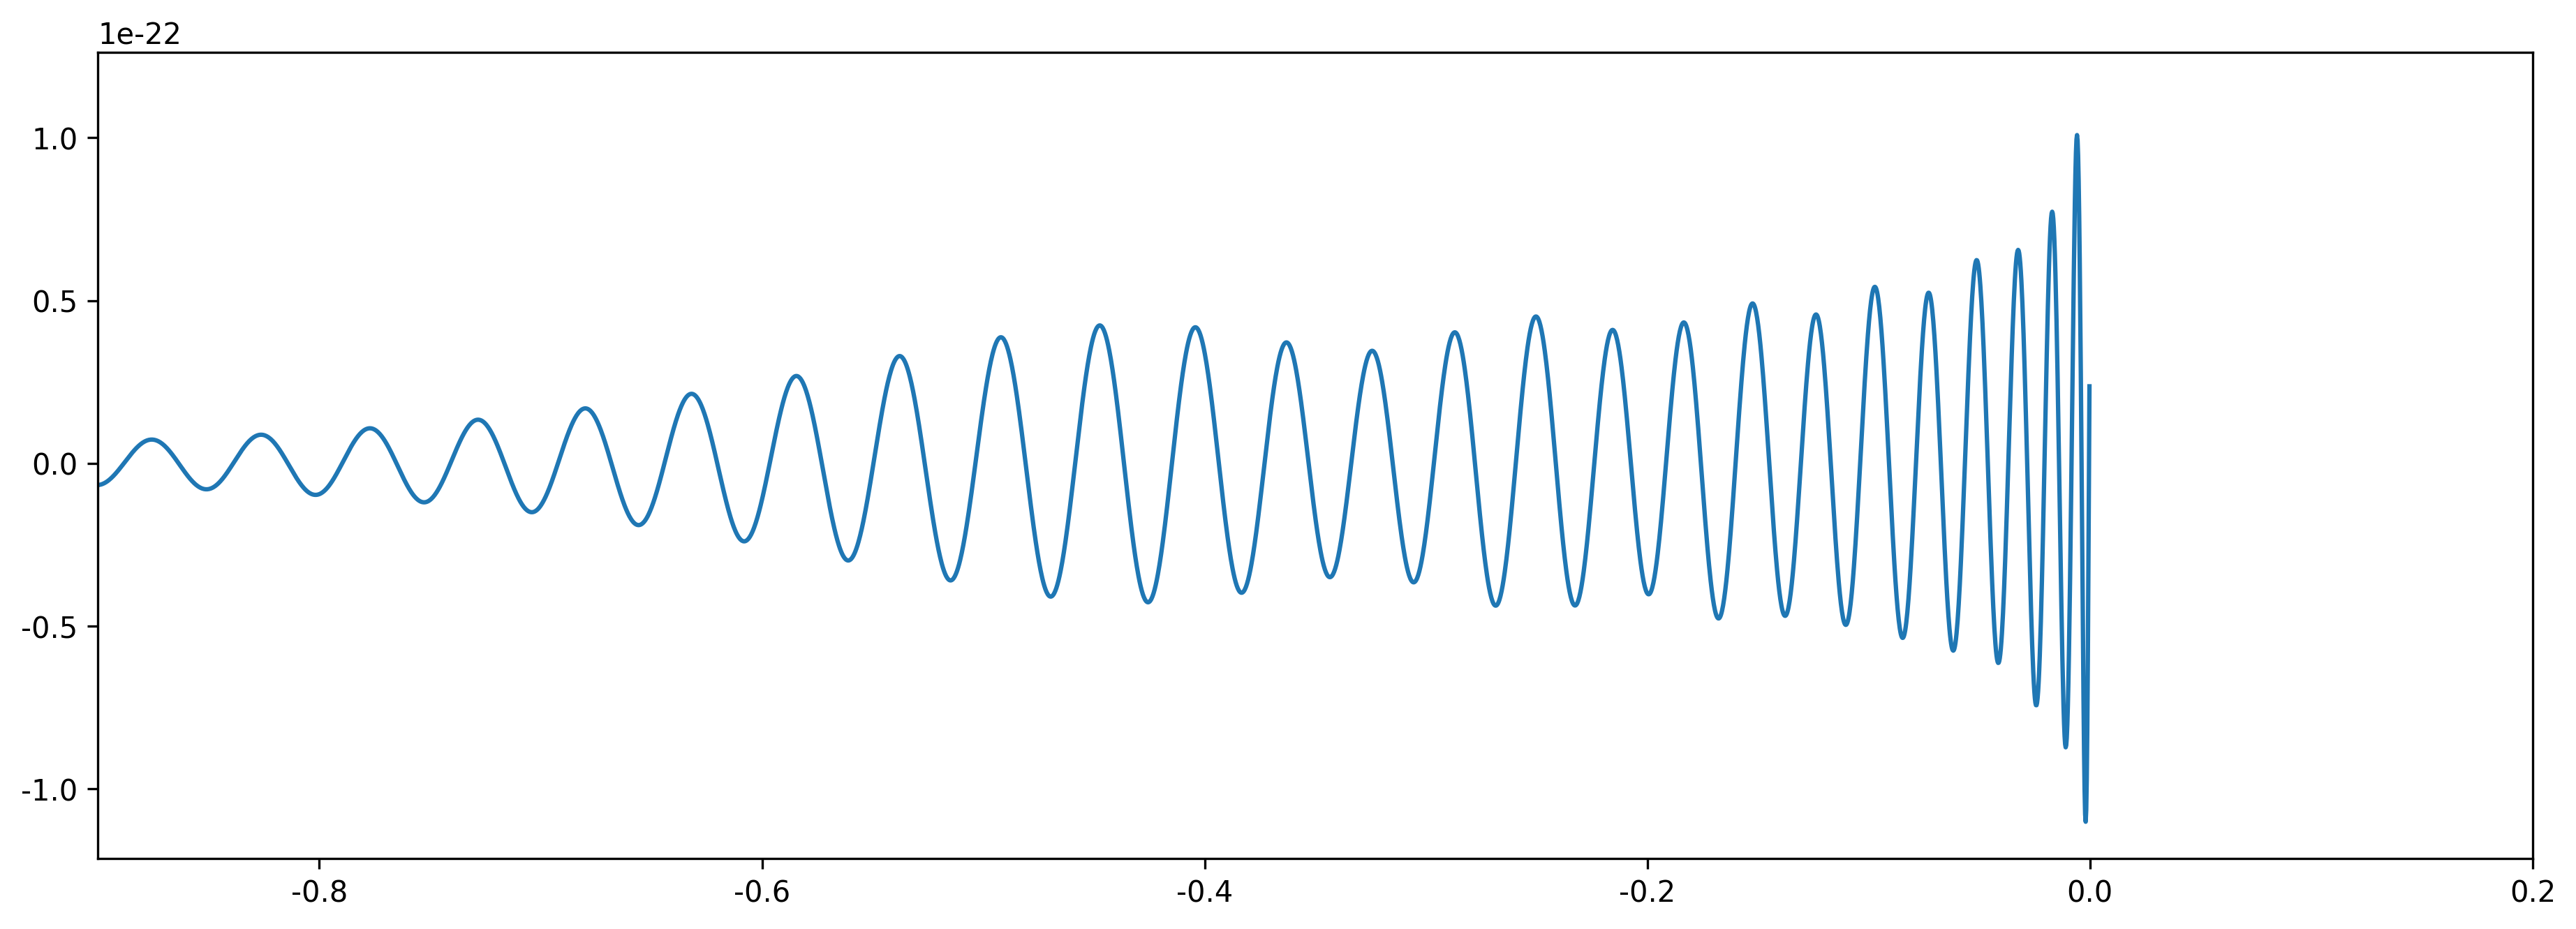

In [112]:
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
w = manual_project_ground_detector(hp_gr.to_timeseries().data,
                                hc_gr.to_timeseries().data,
                                ra=2.321208458632003,
                                dec=-1.1482716840472416,
                                polarization=np.pi/6)

pp.plot(hp_gr.to_timeseries().sample_times, w)
pp.xlim(-0.9,0.2)

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

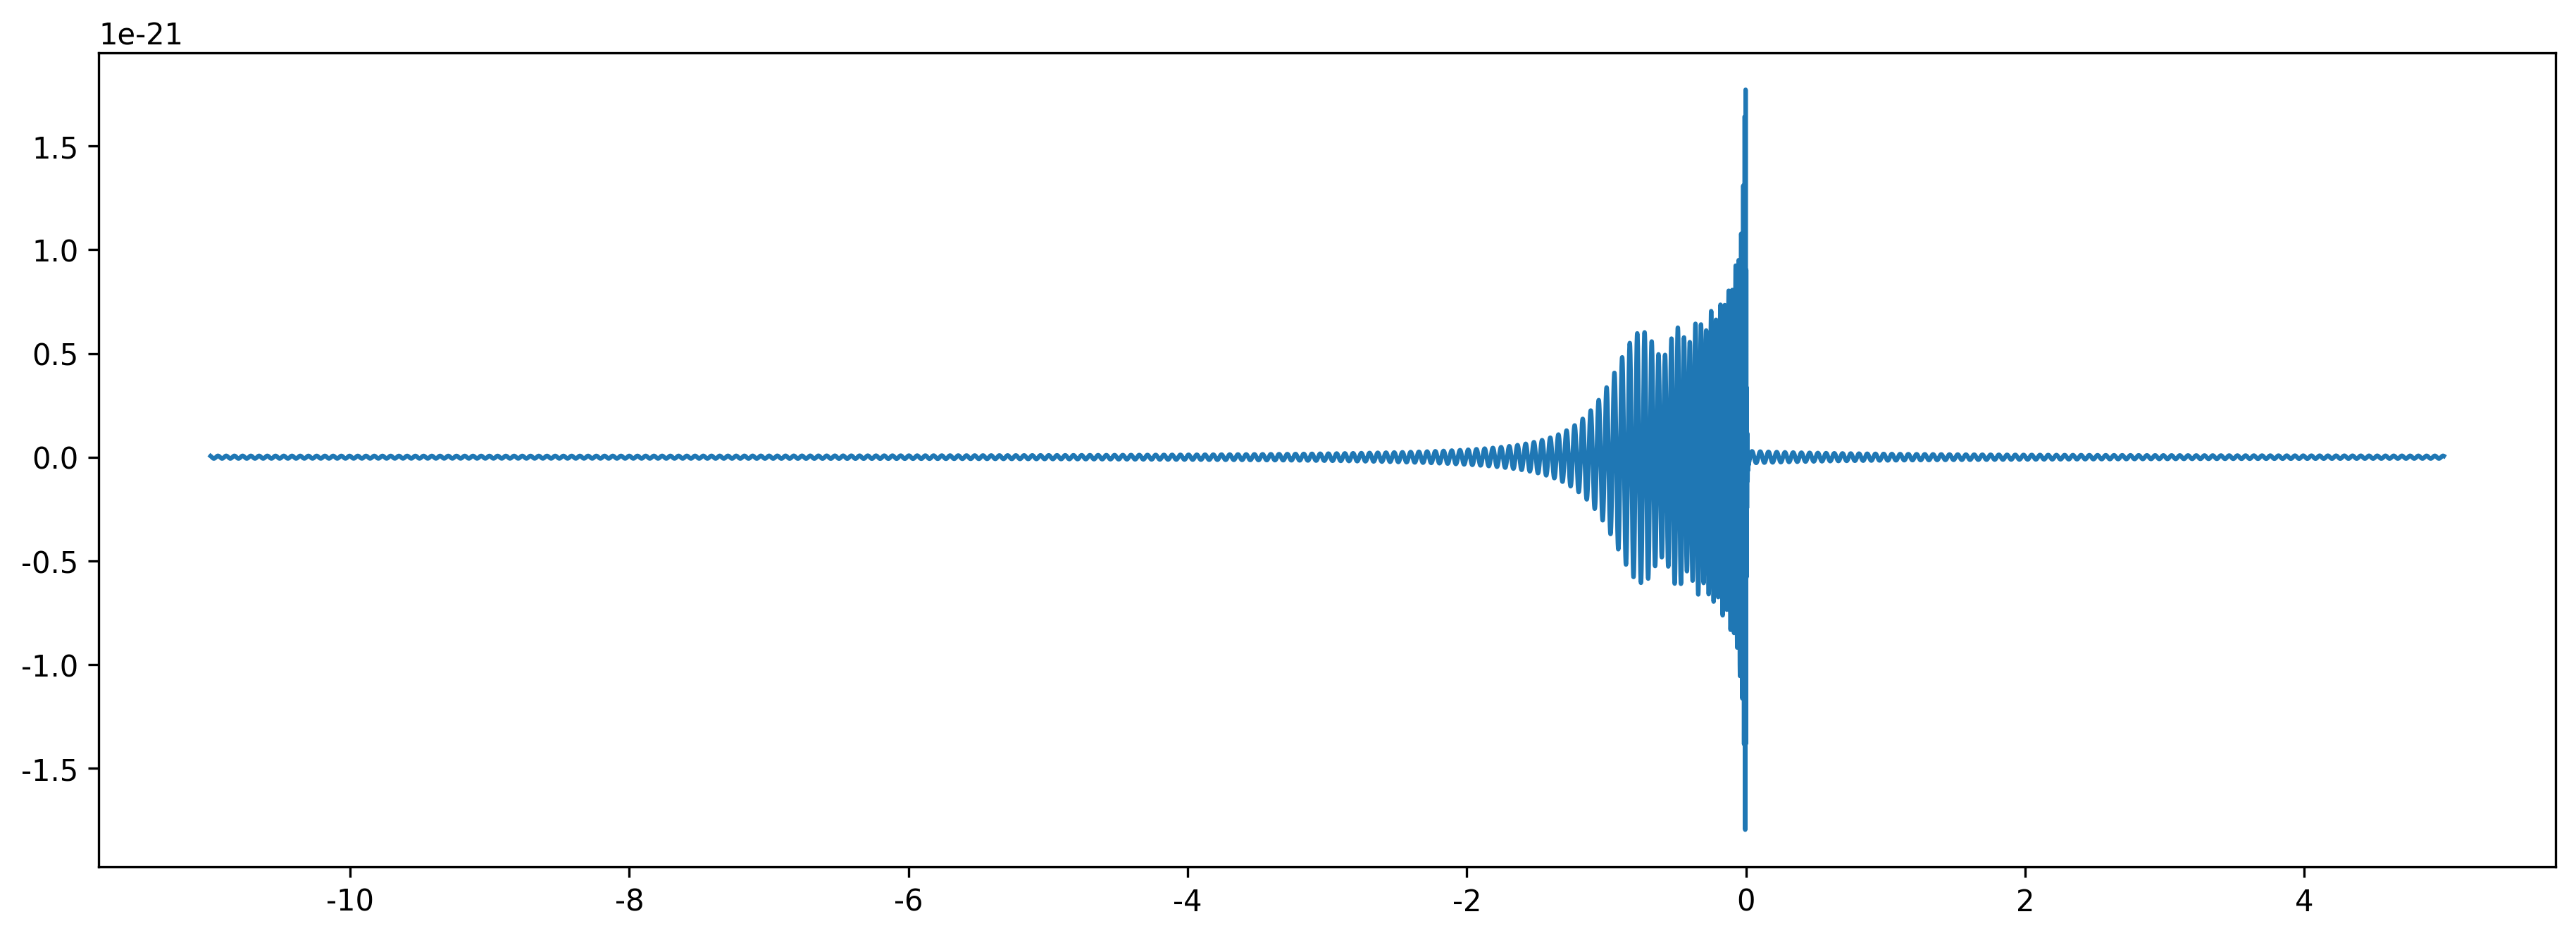

In [113]:
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
pp.plot(hp_gr_td.sample_times, hp_gr_td)
# pp.plot(hhp_td)

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

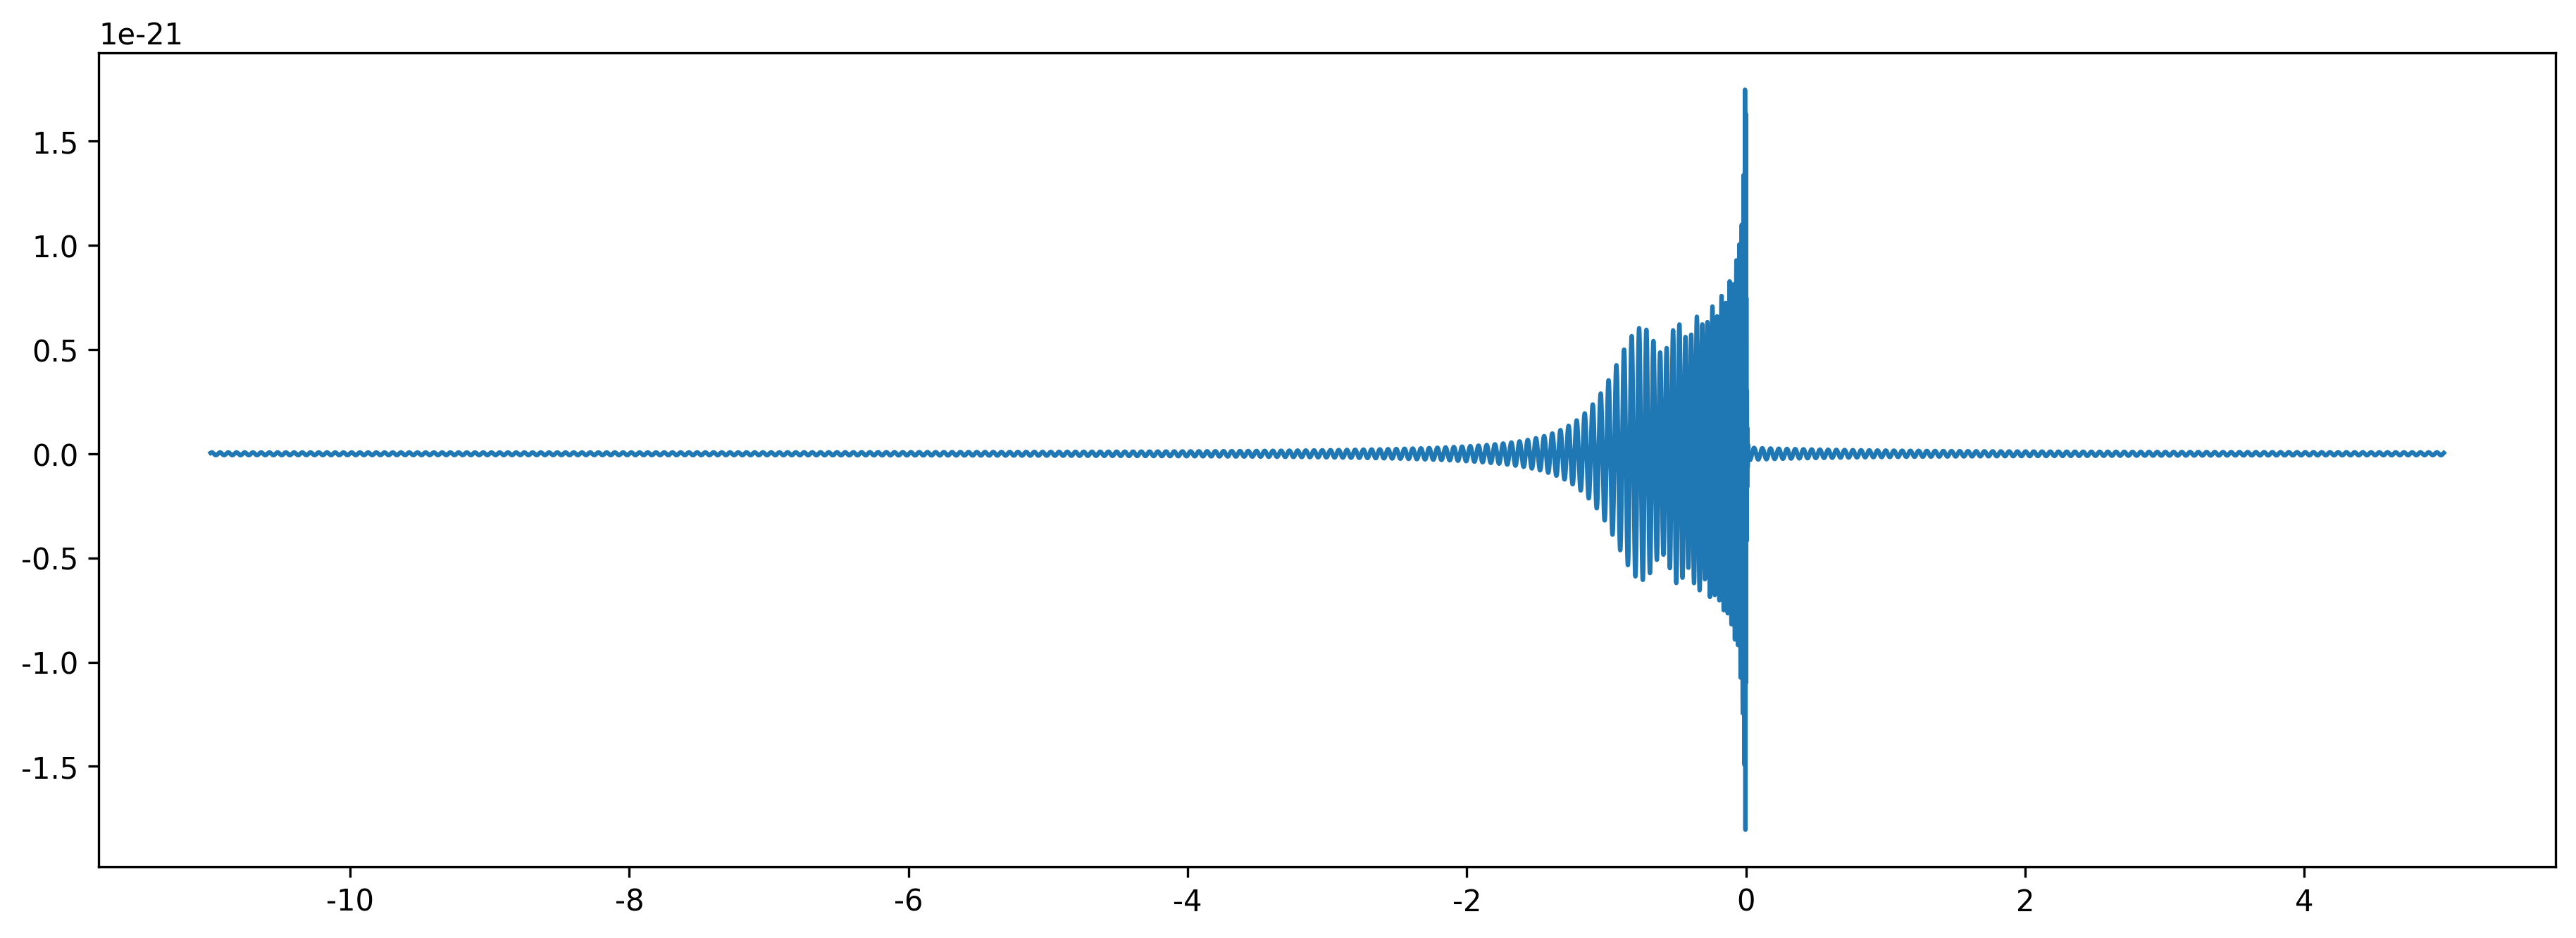

In [114]:
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
pp.plot(hc_gr_td.sample_times, hc_gr_td)

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

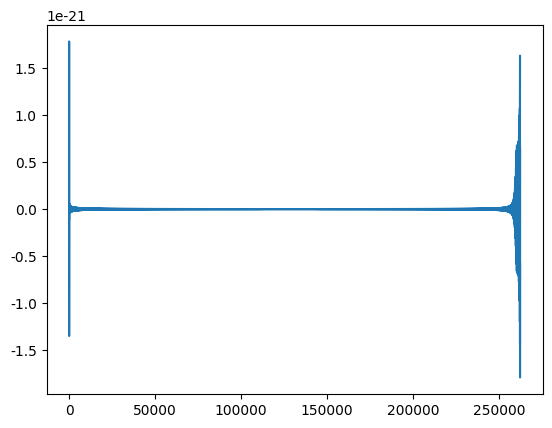

In [115]:
pp.plot(hp_gr.to_timeseries())

In [116]:
pp.plot(manual_project_ground_detector(hhc_td,
                                    hhp_td,
                                    ra=2.321208458632003,
                                    dec=-1.1482716840472416,
                                    polarization=np.pi/6))

ValueError: hp和hc长度不一致！len(hp)=262142, len(hc)=31458

In [ ]:
hhp_ts, hhp_td = manual_fd_to_td(hphc["0"][2][0].data,hphc["0"][2][0].sample_frequencies.data, events["f_final"])
hhc_ts, hhc_td = manual_fd_to_td(hphc["0"][2][1].data,hphc["0"][2][1].sample_frequencies.data, events["f_final"])
# w = detector.Detector("H1").project_wave(tps.TimeSeries(hhc_td, delta_t=hhp_ts[1]-hhp_ts[0]),
#                                 tps.TimeSeries(hhp_td, delta_t=hhc_ts[1]-hhc_ts[0]),
#                                 ra=2.321208458632003,
#                                 dec=-1.1482716840472416,
#                                 polarization=np.pi/6)
w = manual_project_ground_detector(hhc_td,
                                hhp_td,
                                ra=2.321208458632003,
                                dec=-1.1482716840472416,
                                polarization=np.pi/6)

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.


findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

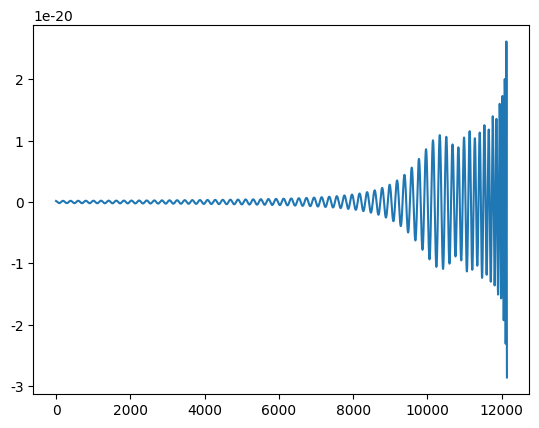

In [ ]:
# pp.plot(hhp_td)
# pp.plot(hhc_td)
# pp.plot(np.concatenate([w[len(hhp_ts)//10*9:], w[:len(hhp_ts)//10]]))
pp.plot(hhp_td[250000:])
# pp.xlim([len(hhp_ts)//10*9:])
# pp.xlim([0,len(hhp_ts)//300])

In [ ]:
# pp.plot(tps.TimeSeries((manual_fd_to_td(hphc["0"][3][0].data,hphc["0"][3][0].sample_frequencies.data, events["f_final"])), delta_t=1/(2*events["f_final"])).data)

In [ ]:
hh_ts, hh_td = manual_fd_to_td(hphc["0"][3][0].data,hphc["0"][3][0].sample_frequencies.data, events["f_final"])
hh_td_tmsrs = tps.TimeSeries(manual_fd_to_td(hphc["0"][3][0].data,hphc["0"][3][0].sample_frequencies.data, events["f_final"])[1], delta_t=hh_ts[1]-hh_ts[0])

In [ ]:
262141 * np.diff(hh_ts)[0]

63.999267578125

In [ ]:
w.end_time

AttributeError: 'numpy.ndarray' object has no attribute 'end_time'

In [117]:
import numpy as np
import matplotlib.pyplot as pp
from matplotlib.colors import LinearSegmentedColormap

# -------------------------- 通用参数定义（请确保这些变量已提前定义） --------------------------
# 示例占位（请替换为你的实际数据）
# hphc = 你的hphc数据结构
# hp_gr = 你的hp_gr数据结构
# deltas = 你的delta列表（如[0.1, 0.2, 0.3]）
# fPhaseMatchIN = 相位匹配频率（如100.5）
# -------------------------------------------------------------------------------------------

# 1. 定义通用参数
order = "gr"
start_index = 15 * 16
end_index = len(hphc[order][0][0].data)  # 统一end_index

# 2. 定义渐变颜色映射（仅需定义一次）
gradient_colors = [
    (0.0, (0, 0, 1)),    # 纯蓝（起始）
    (0.5, (0.5, 0, 0.5)), # 紫色（中间）
    (1.0, (1, 0, 0))     # 纯红（结束）
]
cmap = LinearSegmentedColormap.from_list('blue_to_red', gradient_colors, N=11)
delta_count = len(deltas)

# 3. 创建共享X轴的两张子图（2行1列）
fig, (ax1, ax2) = pp.subplots(
    2, 1, 
    figsize=(6, 8),  # 高度调整为8以容纳两个子图
    dpi=1000, 
    sharex=True,     # 共享X轴（刻度仅显示在下方子图）
    gridspec_kw={'hspace': 0.}  # 子图间垂直间距
)

# -------------------------- 第一张图（上） --------------------------
for i in range(len(deltas)):
    # 数据修正
    hphc[order][i][0][:15*16] = hphc[order][i][0][15*16]
    # 计算颜色
    color = cmap(i / (delta_count - 1) if delta_count > 1 else 0)
    # 绘制相位曲线
    ax1.plot(
        hp_gr.sample_frequencies[start_index:end_index],
        np.unwrap(np.angle(hphc[order][i][0].data))[start_index:],
        color=color,
        label=f"$\\delta=${deltas[i]}",
        linewidth=0.5
    )
    ax1.plot(hp_gr.sample_frequencies[start_index:end_index], np.unwrap(np.angle(hp_gr.data))[start_index:end_index])

# -------------------------- 第二张图（下） --------------------------
for i in range(len(deltas)):
    # 计算颜色（与上图一致）
    color = cmap(i / (delta_count - 1) if delta_count > 1 else 0)
    # 绘制相位差曲线
    ax2.plot(
        hp_gr.sample_frequencies[start_index:end_index],
        (np.unwrap(np.angle(hphc[order][i][0].data))[start_index:end_index] - 
         np.unwrap(np.angle(hp_gr.data))[15*16:end_index]),
        color=color,
        linewidth=0.5
        # 此处不重复设置label，避免图例重复
    )
    ax2.set_xscale("log")

# -------------------------- 共用元素：垂直虚线 + 图例 --------------------------
# 绘制垂直虚线（因共享X轴，画在ax1上即可显示在两个子图中）
dashed_line = ax1.axvline(
    x=fPhaseMatchIN, 
    color='k', 
    linestyle='--', 
    linewidth=1.2
)

dashed_line = ax2.axvline(
    x=fPhaseMatchIN, 
    color='k', 
    linestyle='--', 
    linewidth=1.2
)


# 收集所有图例元素（上图的曲线标签 + 虚线标签）
handles, labels = ax1.get_legend_handles_labels()
# 添加虚线的handle和label（确保虚线出现在图例中）
handles.append(dashed_line)
labels.append(f"$f_\\text{{PhaseMatchIN}}=${fPhaseMatchIN:.2f}Hz")

# 创建共用图例（放在第一张图的右下角）
# ax1.legend(
#     handles=handles,
#     labels=labels,
#     loc='lower right',       # 定位：子图的右下角
#     bbox_to_anchor=(1.0, 0.0),  # 锚点：x=1.0（子图右边缘），y=0.0（子图下边缘）
#     borderaxespad=0.2,       # 图例与锚点的间距
#     frameon=True,            # 显示图例边框
#     fontsize=8               # 可选：调整图例字体大小避免遮挡
# )

# 关键修改2：调整图例定位，移到图像右侧外面（垂直居中）
ax1.legend(
    handles=handles,
    labels=labels,
    loc='center left',        # 图例的左侧中心对齐锚点
    bbox_to_anchor=(1.0, 0.5),# 锚点：x=1.0（图像右边缘），y=0.5（图像垂直中心）
    bbox_transform=fig.transFigure,  # 定位基于整个图像（而非ax1子图）
    borderaxespad=0.0,        # 取消图例与锚点的额外间距
    frameon=True,
    fontsize=8
)

# -------------------------- 轴标签与布局优化 --------------------------
# Y轴标签
ax1.set_ylabel(f"Phase $\\varphi_\\text{{IMR}}^{{({order},\\text{{Parameterized}})}}$")
ax2.set_ylabel(f"Phase Difference $\\Delta\\varphi_{{{order}}}$")
# X轴标签（仅下方子图显示）
ax2.set_xlabel("Fourier frequency $f$ (Hz)")

# 调整布局，避免图例被截断（右侧留出少量空间）
# pp.subplots_adjust(right=0.95)  # 右侧留出5%空间给图例
pp.subplots_adjust(right=0.8, hspace=0.0)
# pp.tight_layout()  # 可选：自动调整子图间距（若使用需注释掉上方的subplots_adjust）

# 显示/保存图
# pp.show()
pp.savefig(f"/workspace/chendawww/server/modify_WF4Py/figs/parameterized_phasing/GW150914_like_phasing_and_difference_{order}.pdf", bbox_inches='tight', dpi=500)

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

In [118]:
(np.unwrap(np.angle(hphc[order][2][0].data))[start_index:end_index] - 
         np.unwrap(np.angle(hp_gr.data))[15*16:end_index])

array([0.        , 0.        , 0.        , ..., 3.14159265, 3.14159265,
       3.14159265])

NameError: name 'fPhaseMatchIN' is not defined

findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'WenQuanYi Micro Hei' not found.
findfont: Font family 'SimHei'

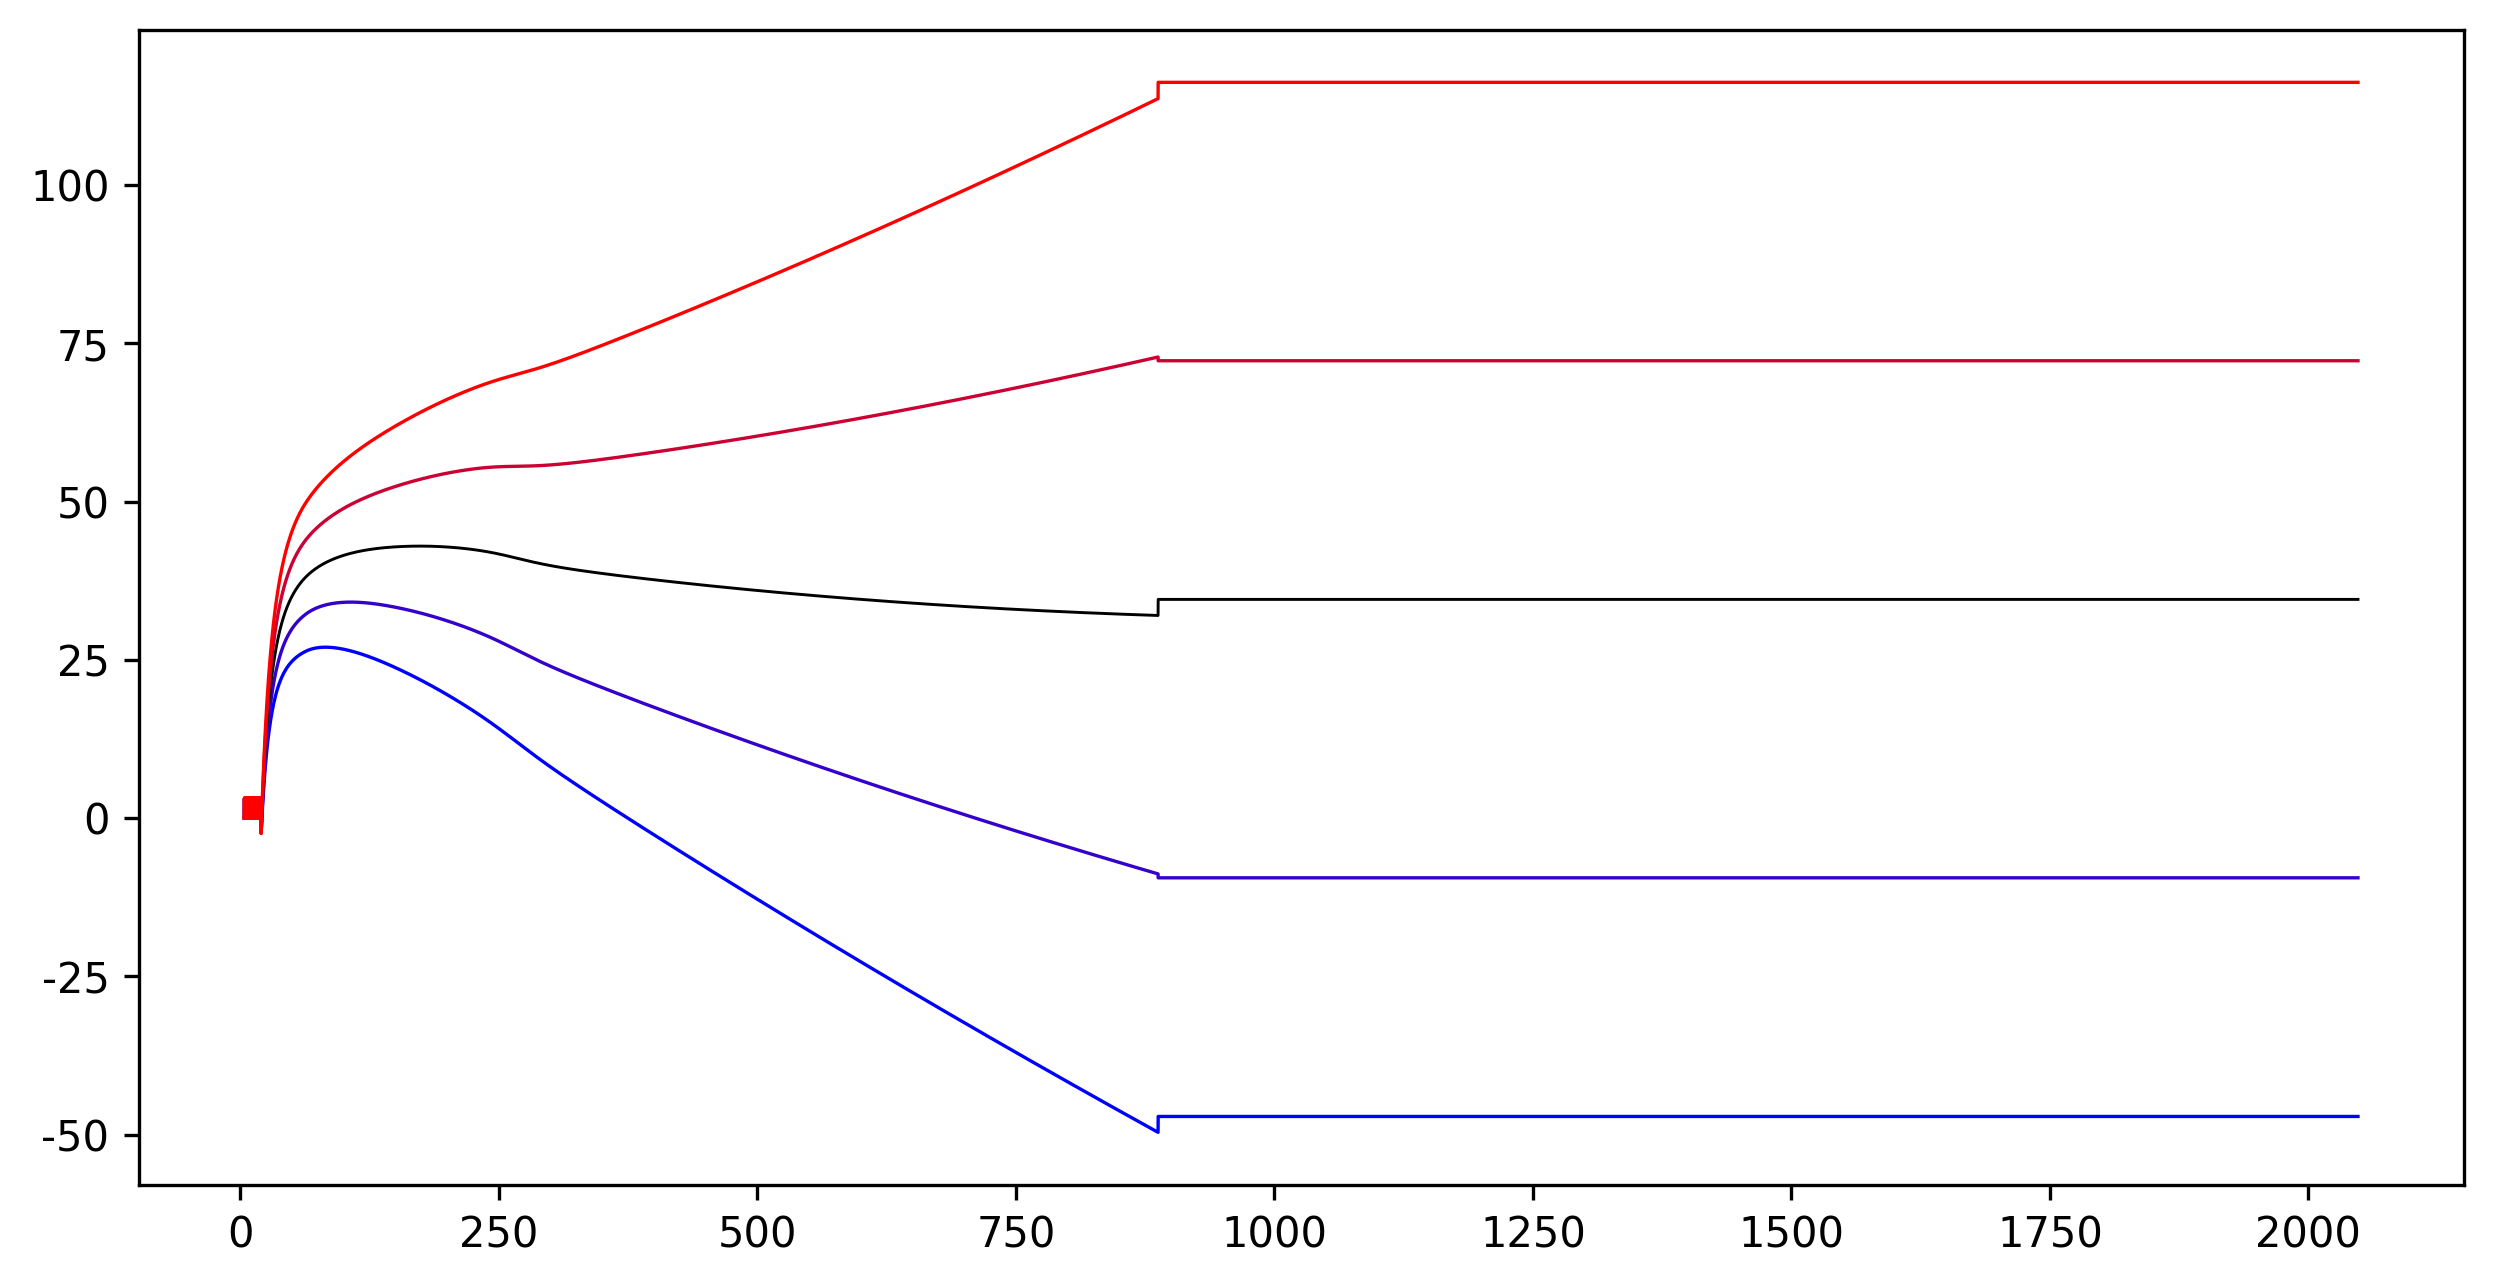

In [ ]:
import numpy as np
import matplotlib.pyplot as pp
from matplotlib.colors import LinearSegmentedColormap

# -------------------------- 通用参数定义（请确保这些变量已提前定义） --------------------------
# 示例占位（请替换为你的实际数据）
# hphc = 你的hphc数据结构
# hp_gr = 你的hp_gr数据结构
# deltas = 你的delta列表（如[0.1, 0.2, 0.3]）
# fPhaseMatchIN = 相位匹配频率（如100.5）
# -------------------------------------------------------------------------------------------

# 1. 定义通用参数
order = "2"
start_index = 15 * 16
end_index = len(hphc[order][0][0].data)  # 统一end_index

# 2. 定义渐变颜色映射（仅需定义一次）
gradient_colors = [
    (0.0, (0, 0, 1)),    # 纯蓝（起始）
    (0.5, (0.5, 0, 0.5)), # 紫色（中间）
    (1.0, (1, 0, 0))     # 纯红（结束）
]
cmap = LinearSegmentedColormap.from_list('blue_to_red', gradient_colors, N=11)
delta_count = len(deltas)

# 3. 创建共享X轴的两张子图（2行1列）
pp.figure(
    figsize=(10,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)

# -------------------------- 第一张图（上） --------------------------
for i in range(len(deltas)):
    # 数据修正
    hphc[order][i][0][:15*16] = hphc[order][i][0][15*16]
    # 计算颜色
    color = cmap(i / (delta_count - 1) if delta_count > 1 else 0)
    # 绘制相位曲线
    if i == len(deltas)//2:
        pp.plot(
            hp_gr.sample_frequencies[start_index:end_index],
            np.unwrap(np.angle(hphc[order][i][0].data))[start_index:],
            color="black",
            label=f"$\\delta=${deltas[i]}, gr",
            linewidth=0.7
        )
        continue
    pp.plot(
        hp_gr.sample_frequencies[start_index:end_index],
        np.unwrap(np.angle(hphc[order][i][0].data))[start_index:],
        color=color,
        label=f"$\\delta=${deltas[i]}",
        linewidth=0.8
    )

# -------------------------- 共用元素：垂直虚线 + 图例 --------------------------
# 绘制垂直虚线（因共享X轴，画在ax1上即可显示在两个子图中）
dashed_line = pp.axvline(
    x=fPhaseMatchIN, 
    color='k', 
    linestyle='--', 
    linewidth=0.5
)

pp.xscale("log")

pp.xlabel("Frequency $f$ (Hz)")
pp.ylabel(f"Phase $\\varphi_\\text{{IMR}}^{{({order},\\text{{Parameterized}})}}$ $(^\circ)$")
# -------------------------- 核心修改：将图例放到图外右侧 --------------------------
# 1. 先获取曲线的图例句柄和标签
handles, labels = pp.gca().get_legend_handles_labels()  # gca()获取当前轴实例
# 2. 添加垂直虚线到图例中（可选，若需要显示虚线说明）
handles.append(dashed_line)
labels.append(f"$f_\\text{{PhaseMatchIN}}$"+"\n"+f"$=${fPhaseMatchIN:.2f}Hz")
# 3. 配置图例外置参数
pp.legend(
    handles=handles,  # 传入包含曲线和虚线的句柄
    labels=labels,    # 传入对应标签
    loc='center left',        # 图例的左中对齐锚点
    bbox_to_anchor=(1.01, 0.5),# 锚点定位：x=1.0（图像右边缘），y=0.5（图像垂直中心）
    frameon=True,             # 显示图例边框
    fontsize=10,              # 图例字体大小
    borderaxespad=0.0         # 取消图例与锚点的额外间距
)

# -------------------------- 布局优化：留出右侧空间给图例 --------------------------
pp.subplots_adjust(right=0.85)  # 右侧留出15%空间（0.85表示图像占85%宽度，剩余给图例）
# 移除无用的hspace参数（单图无需上下子图间距）

pp.title(f"parameterized $\\psi_{{{order}}}$")

pp.xlim([10,1024])

pp.savefig(f"/workspace/chendawww/server/modify_WF4Py/figs/parameterized_phasing/GW150914_like_phasing_{order}.pdf", bbox_inches='tight', dpi=500)

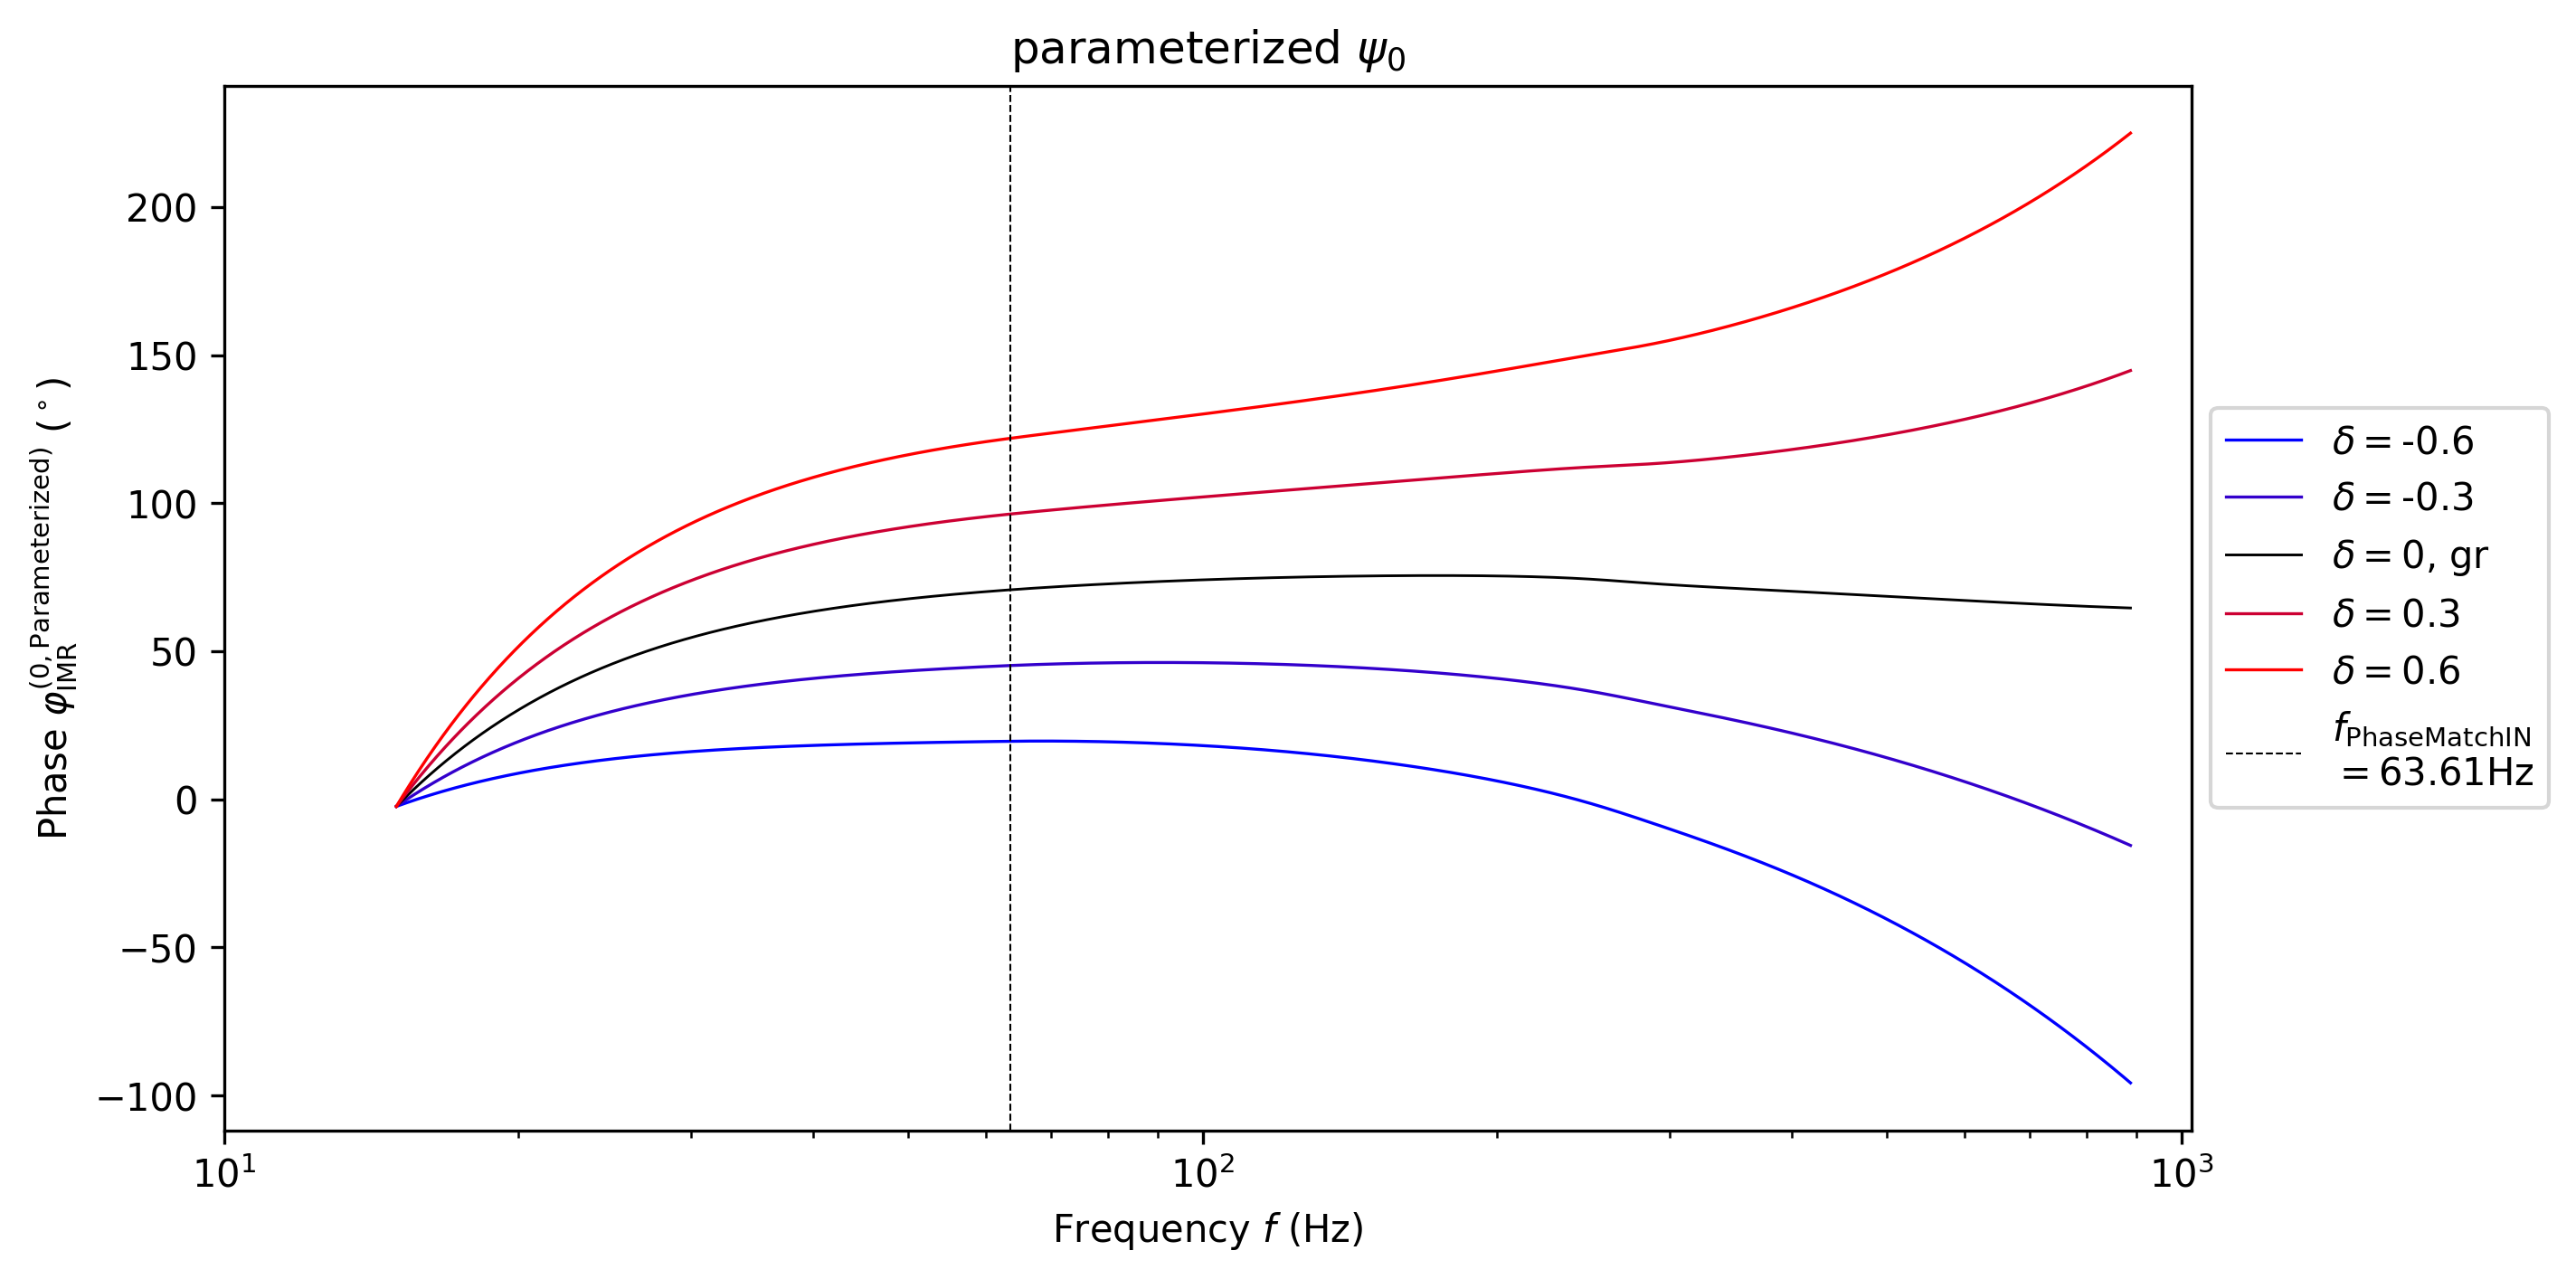

In [ ]:
import numpy as np
import matplotlib.pyplot as pp
from matplotlib.colors import LinearSegmentedColormap

# -------------------------- 通用参数定义（请确保这些变量已提前定义） --------------------------
# 示例占位（请替换为你的实际数据）
# hphc = 你的hphc数据结构
# hp_gr = 你的hp_gr数据结构
# deltas = 你的delta列表（如[0.1, 0.2, 0.3]）
# fPhaseMatchIN = 相位匹配频率（如100.5）
# -------------------------------------------------------------------------------------------

# 1. 定义通用参数
order = "0"
start_index = 15 * 16
end_index = len(hphc[order][0][0].data)  # 统一end_index

# 2. 定义渐变颜色映射（仅需定义一次）
gradient_colors = [
    (0.0, (0, 0, 1)),    # 纯蓝（起始）
    (0.5, (0.5, 0, 0.5)), # 紫色（中间）
    (1.0, (1, 0, 0))     # 纯红（结束）
]
cmap = LinearSegmentedColormap.from_list('blue_to_red', gradient_colors, N=11)
delta_count = len(deltas)

# 3. 创建共享X轴的两张子图（2行1列）
pp.figure(
    figsize=(10,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)

# -------------------------- 第一张图（上） --------------------------
for i in range(len(deltas)):
    # 数据修正
    hphc[order][i][0][:15*16] = hphc[order][i][0][15*16]
    # 计算颜色
    color = cmap(i / (delta_count - 1) if delta_count > 1 else 0)
    # 绘制相位曲线
    if i == len(deltas)//2:
        pp.plot(
            hp_gr.sample_frequencies[start_index:end_index],
            np.unwrap(np.angle(hphc[order][i][0].data))[start_index:],
            color="black",
            label=f"$\\delta=${deltas[i]}, gr",
            linewidth=0.7
        )
        continue
    pp.plot(
        hp_gr.sample_frequencies[start_index:end_index],
        np.unwrap(np.angle(hphc[order][i][0].data))[start_index:],
        color=color,
        label=f"$\\delta=${deltas[i]}",
        linewidth=0.8
    )

# -------------------------- 共用元素：垂直虚线 + 图例 --------------------------
# 绘制垂直虚线（因共享X轴，画在ax1上即可显示在两个子图中）
dashed_line = pp.axvline(
    x=fPhaseMatchIN, 
    color='k', 
    linestyle='--', 
    linewidth=0.5
)

pp.xscale("log")

pp.xlabel("Frequency $f$ (Hz)")
pp.ylabel(f"Phase $\\varphi_\\text{{IMR}}^{{({order},\\text{{Parameterized}})}}$ $(^\circ)$")
# -------------------------- 核心修改：将图例放到图外右侧 --------------------------
# 1. 先获取曲线的图例句柄和标签
handles, labels = pp.gca().get_legend_handles_labels()  # gca()获取当前轴实例
# 2. 添加垂直虚线到图例中（可选，若需要显示虚线说明）
handles.append(dashed_line)
labels.append(f"$f_\\text{{PhaseMatchIN}}$"+"\n"+f"$=${fPhaseMatchIN:.2f}Hz")
# 3. 配置图例外置参数
pp.legend(
    handles=handles,  # 传入包含曲线和虚线的句柄
    labels=labels,    # 传入对应标签
    loc='center left',        # 图例的左中对齐锚点
    bbox_to_anchor=(1.01, 0.5),# 锚点定位：x=1.0（图像右边缘），y=0.5（图像垂直中心）
    frameon=True,             # 显示图例边框
    fontsize=10,              # 图例字体大小
    borderaxespad=0.0         # 取消图例与锚点的额外间距
)

# -------------------------- 布局优化：留出右侧空间给图例 --------------------------
pp.subplots_adjust(right=0.85)  # 右侧留出15%空间（0.85表示图像占85%宽度，剩余给图例）
# 移除无用的hspace参数（单图无需上下子图间距）

pp.title(f"parameterized $\\psi_{{{order}}}$")

pp.xlim([10,1024])

pp.savefig(f"/workspace/chendawww/server/modify_WF4Py/figs/parameterized_phasing/GW150914_like_phasing_{order}.pdf", bbox_inches='tight', dpi=500)

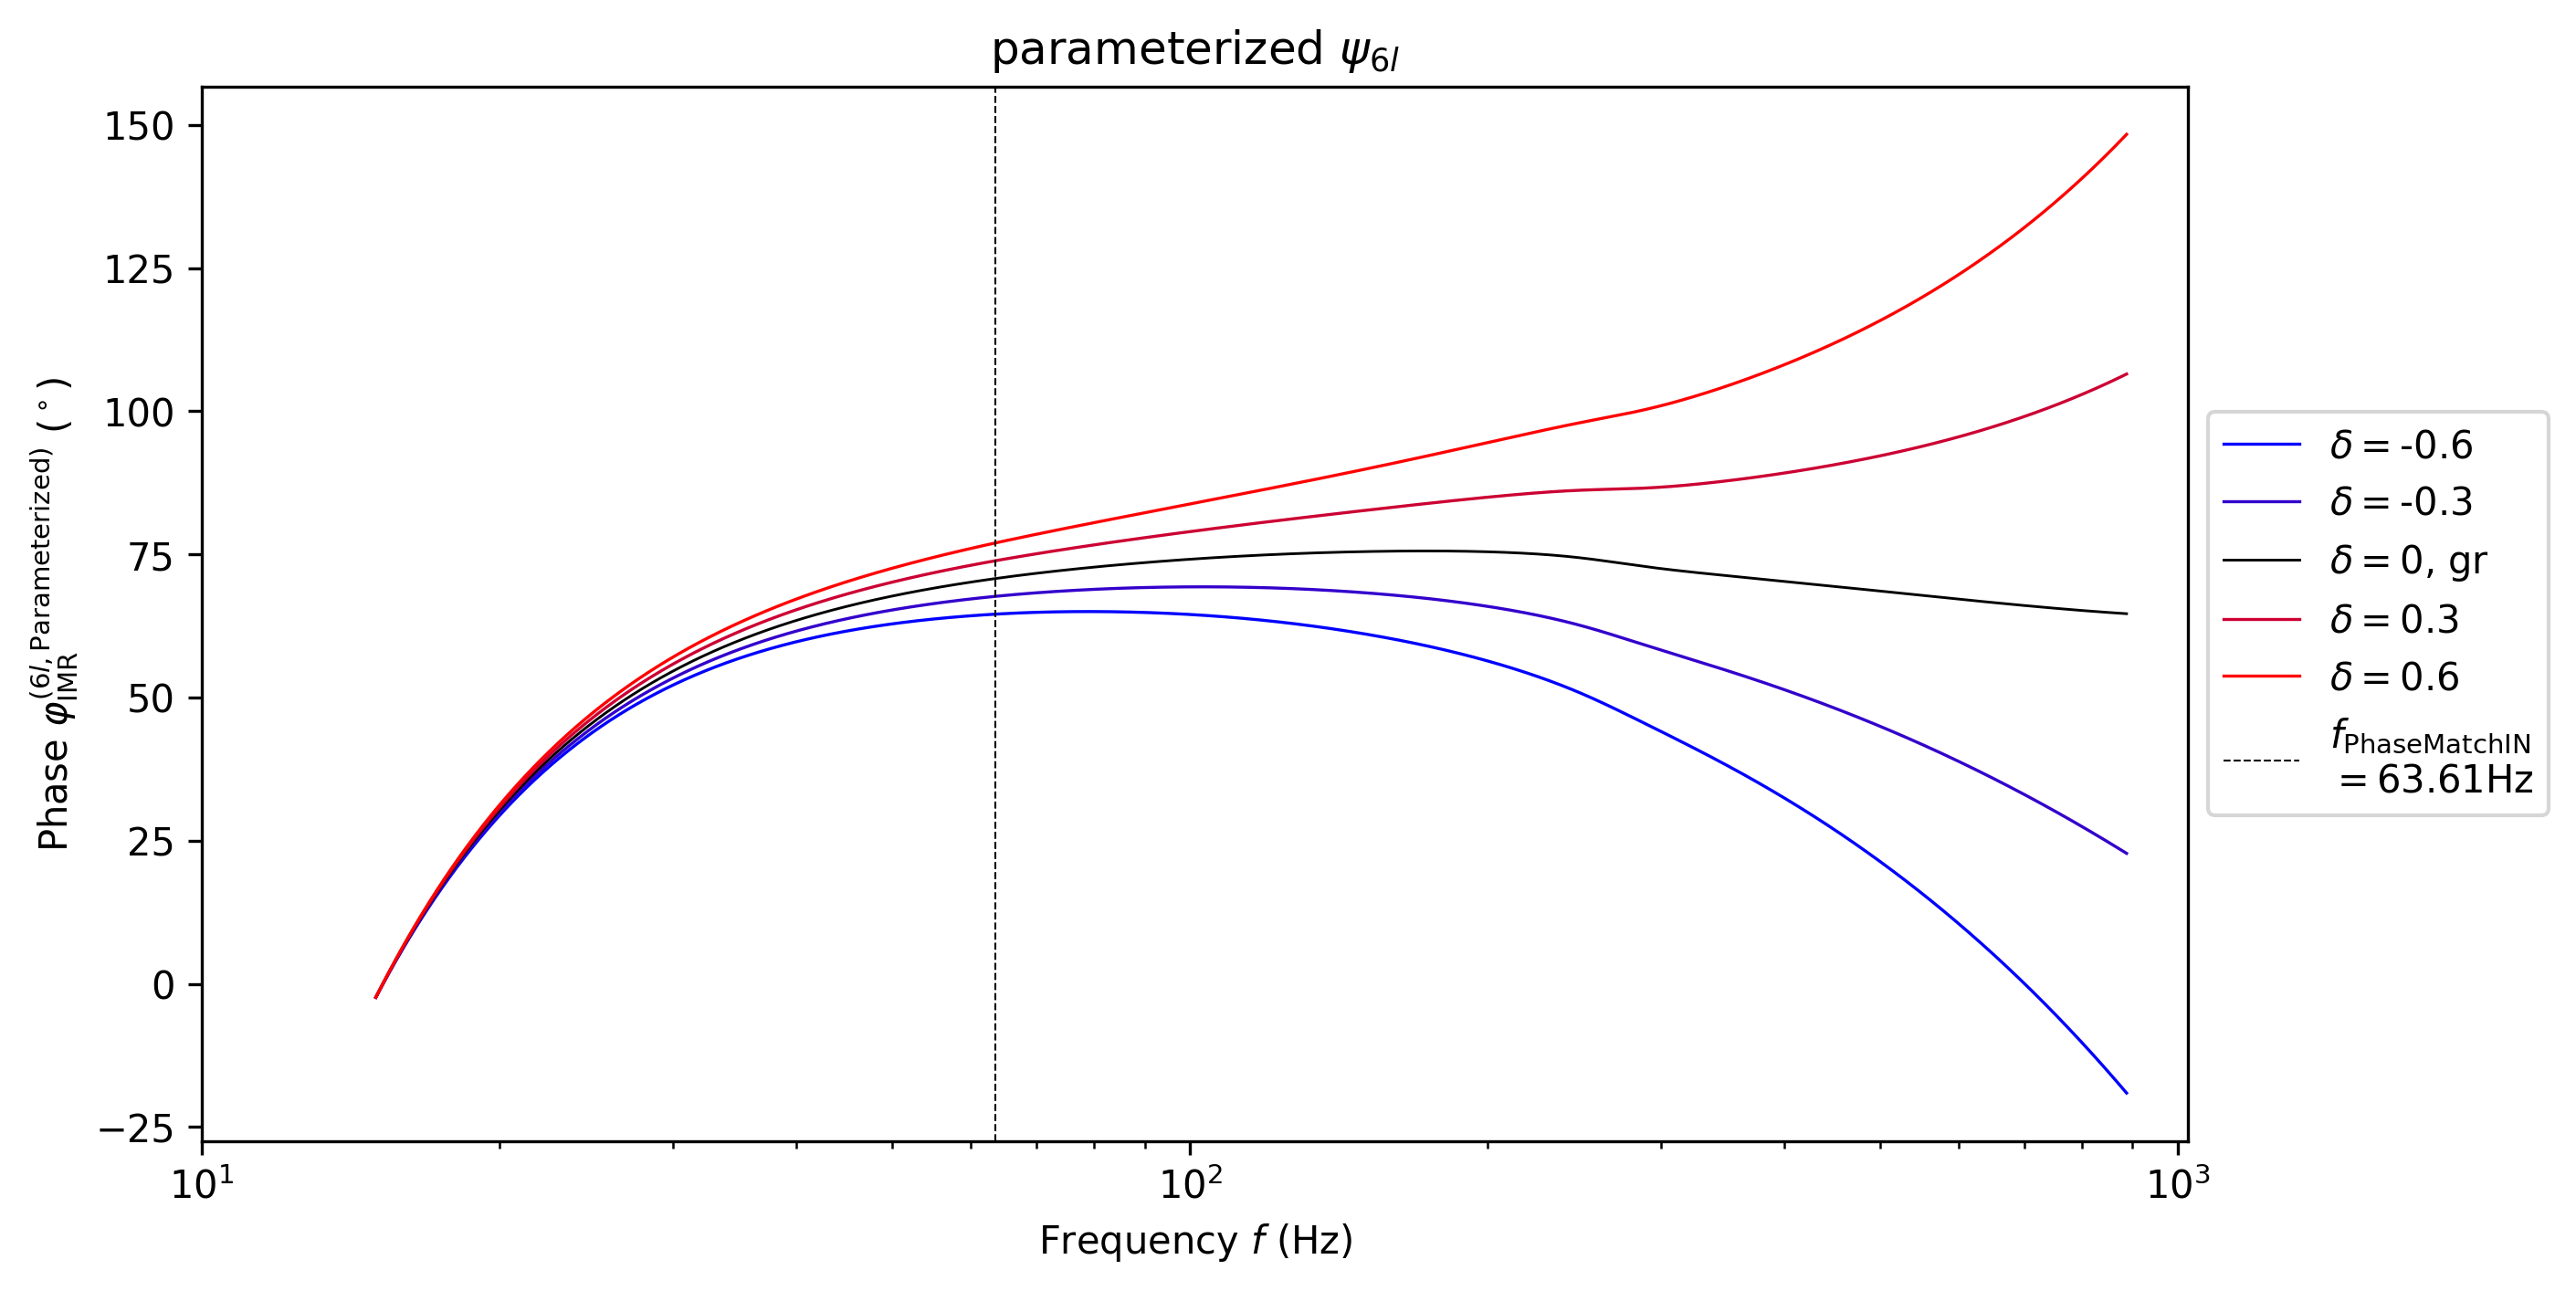

In [ ]:
import numpy as np
import matplotlib.pyplot as pp
from matplotlib.colors import LinearSegmentedColormap

# -------------------------- 通用参数定义（请确保这些变量已提前定义） --------------------------
# 示例占位（请替换为你的实际数据）
# hphc = 你的hphc数据结构
# hp_gr = 你的hp_gr数据结构
# deltas = 你的delta列表（如[0.1, 0.2, 0.3]）
# fPhaseMatchIN = 相位匹配频率（如100.5）
# -------------------------------------------------------------------------------------------

# 1. 定义通用参数
order = "6l"
start_index = 15 * 16
end_index = len(hphc[order][0][0].data)  # 统一end_index

# 2. 定义渐变颜色映射（仅需定义一次）
gradient_colors = [
    (0.0, (0, 0, 1)),    # 纯蓝（起始）
    (0.5, (0.5, 0, 0.5)), # 紫色（中间）
    (1.0, (1, 0, 0))     # 纯红（结束）
]
cmap = LinearSegmentedColormap.from_list('blue_to_red', gradient_colors, N=11)
delta_count = len(deltas)

# 3. 创建共享X轴的两张子图（2行1列）
pp.figure(
    figsize=(10,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)

# -------------------------- 第一张图（上） --------------------------
for i in range(len(deltas)):
    # 数据修正
    hphc[order][i][0][:15*16] = hphc[order][i][0][15*16]
    # 计算颜色
    color = cmap(i / (delta_count - 1) if delta_count > 1 else 0)
    # 绘制相位曲线
    if i == len(deltas)//2:
        pp.plot(
            hp_gr.sample_frequencies[start_index:end_index],
            np.unwrap(np.angle(hphc[order][i][0].data))[start_index:],
            color="black",
            label=f"$\\delta=${deltas[i]}, gr",
            linewidth=0.7
        )
        continue
    pp.plot(
        hp_gr.sample_frequencies[start_index:end_index],
        np.unwrap(np.angle(hphc[order][i][0].data))[start_index:],
        color=color,
        label=f"$\\delta=${deltas[i]}",
        linewidth=0.8
    )

# -------------------------- 共用元素：垂直虚线 + 图例 --------------------------
# 绘制垂直虚线（因共享X轴，画在ax1上即可显示在两个子图中）
dashed_line = pp.axvline(
    x=fPhaseMatchIN, 
    color='k', 
    linestyle='--', 
    linewidth=0.5
)

pp.xscale("log")

pp.xlabel("Frequency $f$ (Hz)")
pp.ylabel(f"Phase $\\varphi_\\text{{IMR}}^{{({order},\\text{{Parameterized}})}}$ $(^\circ)$")
# -------------------------- 核心修改：将图例放到图外右侧 --------------------------
# 1. 先获取曲线的图例句柄和标签
handles, labels = pp.gca().get_legend_handles_labels()  # gca()获取当前轴实例
# 2. 添加垂直虚线到图例中（可选，若需要显示虚线说明）
handles.append(dashed_line)
labels.append(f"$f_\\text{{PhaseMatchIN}}$"+"\n"+f"$=${fPhaseMatchIN:.2f}Hz")
# 3. 配置图例外置参数
pp.legend(
    handles=handles,  # 传入包含曲线和虚线的句柄
    labels=labels,    # 传入对应标签
    loc='center left',        # 图例的左中对齐锚点
    bbox_to_anchor=(1.01, 0.5),# 锚点定位：x=1.0（图像右边缘），y=0.5（图像垂直中心）
    frameon=True,             # 显示图例边框
    fontsize=10,              # 图例字体大小
    borderaxespad=0.0         # 取消图例与锚点的额外间距
)

# -------------------------- 布局优化：留出右侧空间给图例 --------------------------
pp.subplots_adjust(right=0.85)  # 右侧留出15%空间（0.85表示图像占85%宽度，剩余给图例）
# 移除无用的hspace参数（单图无需上下子图间距）

pp.title(f"parameterized $\\psi_{{{order}}}$")

pp.xlim([10,1024])

pp.savefig(f"/workspace/chendawww/server/modify_WF4Py/figs/parameterized_phasing/GW150914_like_phasing_{order}.pdf", bbox_inches='tight', dpi=500)